## §1 Installation

In [1]:
import os
os.environ["SOC_RUN_VERBOSE"] = "0"       # active le run verbeux
os.environ["SOC_CONFIRM_VERBOSE"] = "0"   # confirme les appels API payants

In [2]:
%pip install -q "openai>=1.40" pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


## Configuration et reproductibilité
Tous les réglages qui influencent les tokens sont figés ici et exportés avec les résultats.

Le modèle est épinglé sur un **snapshot daté** et non sur l'alias `gpt-4o`, qui change dans le temps. `SOC_DRY_RUN=1` permet de tester tout le notebook sans appel API, avec des réponses simulées : ces résultats ne doivent jamais être publiés.

In [3]:
import os, json, hashlib, platform, sys, time, random, re, uuid, hmac
import datetime as dt
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd

DRY_RUN = False   # ← mettez True pour un premier test SANS appel API (résultats simulés, non publiables)
DRY_RUN = DRY_RUN or os.environ.get("SOC_DRY_RUN", "0") == "1"

# Modèles × architectures évalués (R1.5 : généralisation et architectures alternatives)
MODELS = ["gpt-4o-2024-08-06", "gpt-4o-mini-2024-07-18"]
ARCHITECTURES = ["multi_agent", "single_agent"]   # 4 agents séquentiels vs 1 appel unique
N_REPEATS   = 3        # répétitions indépendantes par alerte (R2 : repeat-run results)
TEMPERATURE = 0.0
TOP_P       = 1.0
SEED        = 42       # 'seed' OpenAI = déterminisme best-effort ; system_fingerprint est journalisé
MAX_TOKENS  = {"triage": 400, "mitre": 500, "investigation": 900, "reporting": 1200, "single": 2500}

ALERTS_PATH = "alerts_v2.csv"   # 50 alertes d'origine annotées + 25 négatifs difficiles
# v3 : alertes SIEM verbeuses appariées + contrôles de dérive, exécutées dans un run SÉPARÉ
VERBOSE_ALERTS_PATH = "alerts_verbose.csv"
VERBOSE_RUN_ID = "dryrun_verbose" if DRY_RUN else "run_verbose"
RUN_VERBOSE = os.environ.get("SOC_RUN_VERBOSE", "0") == "1" or DRY_RUN   # exécuter (ou reprendre) le run verbeux
REF_RUN_ID = "run_final"   # run de référence publié (alertes courtes)
HUMAN_MEASUREMENTS_PATH = "human_measurements.csv"   # optionnel 

# RUN_ID FIXE => relancer le notebook reprend là où il s'était arrêté (les traitements faits ne sont pas refaits)
RUN_ID  = os.environ.get("SOC_RUN_ID") or ("dryrun_test" if DRY_RUN else "run_final")
OUT_DIR = Path("outputs") / RUN_ID
OUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
RNG = np.random.default_rng(SEED)
print(f"Dossier de travail : {Path.cwd()}")
print(f"RUN_VERBOSE={RUN_VERBOSE} (dossier outputs/{VERBOSE_RUN_ID})")
print(f"RUN_ID={RUN_ID} | DRY_RUN={DRY_RUN} | modèles={MODELS} | architectures={ARCHITECTURES} | répétitions={N_REPEATS}")
if DRY_RUN:
    print("⚠️  MODE SIMULÉ : les chiffres produits ne sont PAS des mesures.")

Dossier de travail : C:\Users\a847071\Downloads\soc-energy-repo
RUN_VERBOSE=False (dossier outputs/run_verbose)
RUN_ID=run_final | DRY_RUN=False | modèles=['gpt-4o-2024-08-06', 'gpt-4o-mini-2024-07-18'] | architectures=['multi_agent', 'single_agent'] | répétitions=3


## Paramètres d'estimation : valeur centrale, plage et **source**

### Chaque paramètre a une valeur centrale (`central`) et une plage (`low` / `high`), utilisées par le Monte Carlo et l'analyse de sensibilité.


In [4]:
PARAMS = {

    # "HYPOTHÈSE" = choix de modélisation sans source publiée : le justifier par l'analyse de sensibilité.
    # --- Estimateur E1 : énergie par requête (benchmark publié) ---------------------------
    "E_QUERY_WH":        dict(central=0.31, low=0.16, high=0.60, unit="Wh/requête", includes_pue=True,
                              source="Réf. [6] : Oviedo et al., 'Energy use of AI inference, efficiency pathways, and test-time scaling', Joule, 2026, doi:10.1016/j.joule.2026.102430 (arXiv:2509.20241) : médiane 0,31 Wh/requête (IQR 0,16–0,60), requête type 500 tokens entrée / 300 sortie ; PUE INCLUS (log-normale P5–P95 1,05–1,40)",
                              note="Plage = IQR publié. Pour GPT-4o mini, multiplié par le rapport Jegham [12] mini/4o (E1_FACTOR)."),
    # --- Estimateur E2 : énergie par token, source INDÉPENDANTE ---------------------
    "E_OUT_J_PER_TOKEN": dict(central=3.5, low=1.0, high=4.0, unit="J/token de sortie", includes_pue=False,
                              source="Réf. [10] : Samsi et al., 'From Words to Watts: Benchmarking the Energy Costs of Large Language Model Inference', IEEE HPEC 2023 : ≈ 3–4 J par token de sortie, LLaMA-65B, énergie GPU seule (sans PUE)",
                              note="Borne basse 1 J : matériel plus récent et batching en production (HYPOTHÈSE)."),
    "PREFILL_RATIO":     dict(central=0.13, low=0.05, high=0.30, unit="ratio",
                              source="Dérivé de la réf. [12] (Jegham et al., Table 4 : ajustement linéaire sur les 3 tailles de prompt GPT-4o : ≈ 0,47 J/token entrée vs 3,5 J/token sortie) — calcul reproduit au §3/§12",
                              note="Énergie d'un token d'entrée / énergie d'un token de sortie."),
    "PUE":               dict(central=1.12, low=1.09, high=1.54, unit="-",
                              source="Central : PUE Azure 1,12 (réf. [12], Table 1, d'après Microsoft). Haut : moyenne mondiale 1,54, Uptime Institute Global Data Center Survey 2025 (UII Keynote Report 180, juillet 2025) — remplace la réf. [37] erronée",
                              note="Appliqué UNIQUEMENT aux coefficients avec includes_pue=False (ici E2)."),
    # --- Intensités carbone séparées --------------------------------------------------
    "CI_CLOUD":          dict(central=350, low=250, high=435, unit="gCO2e/kWh",
                              source="0,35 kgCO2e/kWh pour l'inférence OpenAI sur Azure (réf. [12], Table 1, d'après le rapport de durabilité Microsoft) ; haut = moyenne mondiale IEA 2025 (réf. [41])",
                              note="Réseau du datacenter (inférence)."),
    "CI_WORKSTATION":    dict(central=435, low=50, high=750, unit="gCO2e/kWh",
                              source="Réf. [41] : IEA, Electricity 2026, chapitre Emissions : intensité mondiale moyenne = 435 gCO2/kWh en 2025, 360 en 2030 (445 en 2024 selon IEA Electricity 2025). Maroc : 536 gCO2e/kWh (LowCarbonPower.org, données Ember, avr. 2025–mars 2026)",
                              note="Réseau du pays du SOC (postes analystes). Plage = réseaux bas carbone → fortement carbonés."),
    # --- Baseline humaine -------------------------------------------------------
    "WS_POWER_W":        dict(central=120, low=70, high=250, unit="W",
                              source="Ordinateur de bureau actif 36–250 W (moyenne 55 W) et écran LCD 15–35 W : synthèse DSSW 'Review of Computer Energy Consumption' (Kawamoto et al. 2001/2004, Roberson et al. 2002). Central = 1 PC + 2 écrans. IDÉAL : mesure au wattmètre",
                              note="Poste + écrans en usage actif."),
    "WS_ATTRIBUTION":    dict(central=1.0, low=0.5, high=1.0, unit="fraction",
                              source="HYPOTHÈSE de modélisation (charge partagée), testée en sensibilité",
                              note="Part du poste attribuable à UNE alerte (<1 = investigations en parallèle)."),
    "HUMAN_MIN_TRIAGE_L1":   dict(central=20, low=10, high=45, unit="min/alerte",
                              source="HYPOTHÈSE (scénario conservateur, triage L1 seul), testée en sensibilité ; à remplacer par une mesure si possible",
                              note="Scénario conservateur : triage niveau 1 seulement."),
    "HUMAN_MIN_FULL_INVEST": dict(central=70, low=30, high=240, unit="min/alerte",
                              source="'The State of AI in the SOC 2025' (enquête auprès de 282 responsables sécurité, rapportée par The Hacker News, sept. 2025) : 70 min en moyenne pour investiguer complètement une alerte. Haut = 4 h (borne haute de la source 2–4 h du manuscrit)",
                              note="Remplace 250 min (non justifié)."),
    "HUMAN_REVIEW_MIN":  dict(central=15, low=5, high=30, unit="min/alerte",
                              source="HYPOTHÈSE (relecture humaine du rapport IA), testée en sensibilité",
                              note="Relecture humaine résiduelle (scénario hybride)."),
    "CLIENT_W":          dict(central=30, low=10, high=60, unit="W",
                              source="HYPOTHÈSE (ordinateur portable pendant la latence API) ; impact négligeable (§16)",
                              note="Machine qui orchestre le pipeline."),
    # --- SOAR & extrapolations -------------------------------------------------------------
    "SOAR_CPU_W":        dict(central=30, low=10, high=65, unit="W",
                              source="HYPOTHÈSE (puissance CPU d'un serveur attribuée au playbook) ; le temps CPU est mesuré (§11)"),
    "ALERTS_PER_YEAR":   dict(central=10_000, low=10_000, high=10_000, unit="alertes/an",
                              source="Unité de normalisation (résultats exprimés pour 10 000 alertes investiguées) ; ordre de grandeur réel : 960 alertes/jour en moyenne (State of AI in the SOC 2025)",
                              note="Fixe : le lecteur met à l'échelle selon son volume."),
    "REASONING_TOKEN_MULT": dict(central=8, low=3, high=20, unit="x tokens de sortie",
                              source="HYPOTHÈSE (PROJECTION, non mesurée)",
                              note="Extended reasoning."),
    # --- cycle de vie -----------------------------------------
    "EMB_SERVER_KG":     dict(central=3700, low=2500, high=6000, unit="kgCO2e/nœud 8 GPU",
                              source="Luccioni, Viguier & Ligozat, 'Estimating the Carbon Footprint of BLOOM, a 176B Parameter Language Model', JMLR 24(253), 2023 : ≈ 150 kgCO2e par GPU et ≈ 2 500 kgCO2e par nœud serveur hors GPU → 8×150 + 2 500 ≈ 3 700 kg",
                              note="Carbone incorporé (fabrication) d'un nœud d'inférence."),
    "SERVER_POWER_KW":   dict(central=6.0, low=4.0, high=10.2, unit="kW",
                              source="HYPOTHÈSE ; borne haute = puissance max. d'un DGX H100 (fiche technique NVIDIA) — À VÉRIFIER",
                              note="Puissance électrique moyenne du nœud en service."),
    "HW_LIFETIME_Y":     dict(central=5, low=3, high=6, unit="ans",
                              source="HYPOTHÈSE (durée d'amortissement des serveurs) — À VÉRIFIER dans les rapports annuels des hyperscalers",
                              note=""),
    "SERVER_UTIL":       dict(central=0.5, low=0.3, high=0.8, unit="fraction",
                              source="HYPOTHÈSE (taux d'utilisation moyen) ; testée en sensibilité",
                              note="Répartit le carbone incorporé sur l'énergie réellement servie."),
       "WS_EMB_KG":         dict(central=305, low=213, high=457, unit="kgCO2e/poste",
                              source="Dell, Life Cycle Assessment OptiPlex Tower 7020 (Feb. 2024): 94+10+6 kg; Dell, Life Cycle Assessment P2425H (Mar. 2024): 80.72+12.72+4.04 kg x 2 monitors; EU baseline, manufacturing + distribution + end-of-life, use phase excluded; range -30%/+50% (assumed)",
                              note="Carbone incorporé du poste analyste (1 PC + 2 écrans)."),
    "WS_LIFETIME_Y":     dict(central=4, low=3, high=6, unit="ans",
                              source="HYPOTHÈSE (cycle de renouvellement du parc)"),
    "WS_HOURS_PER_YEAR": dict(central=1800, low=1600, high=2500, unit="h/an",
                              source="HYPOTHÈSE (heures d'utilisation ; borne haute = poste partagé en SOC 24/7)"),
    "WUE_ONSITE_L_PER_KWH": dict(central=0.30, low=0.18, high=0.55, unit="L/kWh",
                              source=" central : WUE sur site Azure utilisé par Jegham et al. [12] (Table 1) ; haut : Li, Yang, Islam & Ren, 'Making AI Less Thirsty', arXiv:2304.03271 (moyenne US)",
                              note="Eau consommée sur site (refroidissement du datacenter)."),
    "EWIF_L_PER_KWH":    dict(central=3.1, low=1.0, high=4.5, unit="L/kWh",
                              source="Li et al., 'Making AI Less Thirsty', arXiv:2304.03271 : facteur d'intensité hydrique de l'électricité (moyenne US ≈ 3,1 L/kWh) ; dépend fortement du mix",
                              note="Eau consommée hors site (production de l'électricité), pour le cloud ET le poste."),
}
N_QUERIES_THEORETICAL = 12   # modèle théorique du manuscrit, présenté séparément (§12)

# Benchmark par modèle : Jegham et al., arXiv:2505.09598, Table 4 — [tokens entrée, tokens sortie, Wh/requête], PUE 1,12 inclus.
# NB : Jegham estime GPT-4o mini PLUS énergivore que GPT-4o, car il le suppose servi sur DGX A100 (vs H100 pour GPT-4o).
#      C'est une hypothèse matérielle de la source, à mentionner si vous comparez les deux modèles
JEGHAM_T4 = {

    "gpt-4o-2024-08-06":      [[100, 300, 0.423], [1000, 1000, 1.215], [10000, 1500, 2.875]],
    "gpt-4o-mini-2024-07-18": [[100, 300, 0.577], [1000, 1000, 1.897], [10000, 1500, 3.098]],
}
REF_MODEL = "gpt-4o-2024-08-06"   # E1_FACTOR = benchmark Jegham [12] du modèle / celui de GPT-4o (prompt court)
E1_FACTOR = {m: t[0][2] / JEGHAM_T4[REF_MODEL][0][2] for m, t in JEGHAM_T4.items()}
JFIT = {m: np.linalg.solve(np.c_[np.array(t)[:, :2], np.ones(3)], np.array(t)[:, 2]) for m, t in JEGHAM_T4.items()}
for m in MODELS:
    if m not in JEGHAM_T4:
        print(f"⚠️  {m} absent de JEGHAM_T4 : E1 utilisera les coefficients de {REF_MODEL} (à compléter).")
    else:
        a, b, c = JFIT[m]
        print(f"{m}: E1 = {JEGHAM_T4[m][0][2]} Wh/requête courte | ajustement : {a*3600:.2f} J/token entrée, "
              f"{b*3600:.2f} J/token sortie, {c:.3f} Wh fixe")
print("E2 (Samsi et al.) est indépendant du modèle : il compare les ARCHITECTURES, pas GPT-4o vs mini.")

CENTRAL = {k: v["central"] for k, v in PARAMS.items()}
params_df = pd.DataFrame(PARAMS).T[["central", "low", "high", "unit", "source", "note"]]
missing = params_df.index[params_df["source"].str.strip() == ""].tolist()
to_verify = params_df.index[params_df["source"].str.contains("À VÉRIFIER")].tolist()

params_df

gpt-4o-2024-08-06: E1 = 0.423 Wh/requête courte | ajustement : 0.47 J/token entrée, 3.47 J/token sortie, 0.121 Wh fixe
gpt-4o-mini-2024-07-18: E1 = 0.577 Wh/requête courte | ajustement : 0.11 J/token entrée, 6.65 J/token sortie, 0.020 Wh fixe
E2 (Samsi et al.) est indépendant du modèle : il compare les ARCHITECTURES, pas GPT-4o vs mini.


,central,low,high,unit,source,note
E_QUERY_WH,0.31,0.16,0.6,Wh/requête,"Réf. [6] : Oviedo et al., 'Energy use of AI in...","Plage = IQR publié. Pour GPT-4o mini, multipli..."
E_OUT_J_PER_TOKEN,3.5,1.0,4.0,J/token de sortie,"Réf. [10] : Samsi et al., 'From Words to Watts...",Borne basse 1 J : matériel plus récent et batc...
PREFILL_RATIO,0.13,0.05,0.3,ratio,"Dérivé de la réf. [12] (Jegham et al., Table 4...",Énergie d'un token d'entrée / énergie d'un tok...
PUE,1.12,1.09,1.54,-,"Central : PUE Azure 1,12 (réf. [12], Table 1, ...",Appliqué UNIQUEMENT aux coefficients avec incl...
CI_CLOUD,350,250,435,gCO2e/kWh,"0,35 kgCO2e/kWh pour l'inférence OpenAI sur Az...",Réseau du datacenter (inférence).
CI_WORKSTATION,435,50,750,gCO2e/kWh,"Réf. [41] : IEA, Electricity 2026, chapitre Em...",Réseau du pays du SOC (postes analystes). Plag...
WS_POWER_W,120,70,250,W,Ordinateur de bureau actif 36–250 W (moyenne 5...,Poste + écrans en usage actif.
WS_ATTRIBUTION,1.0,0.5,1.0,fraction,"HYPOTHÈSE de modélisation (charge partagée), t...",Part du poste attribuable à UNE alerte (<1 = i...
HUMAN_MIN_TRIAGE_L1,20,10,45,min/alerte,"HYPOTHÈSE (scénario conservateur, triage L1 se...",Scénario conservateur : triage niveau 1 seulem...
HUMAN_MIN_FULL_INVEST,70,30,240,min/alerte,'The State of AI in the SOC 2025' (enquête aup...,Remplace 250 min (non justifié).


##* Client API
La clé est lue uniquement depuis l'environnement. En mode simulé, un faux client renvoie des réponses plausibles pour tester la chaîne de traitement.

In [5]:
class _MockCompletions:
    """Faux client pour tester le notebook sans appel API (DRY_RUN). Résultats NON publiables."""
    KEYWORDS = {"mimikatz": "T1003", "powershell": "T1059", "encoded": "T1027", "lsass": "T1003",
                "brute": "T1110", "failed login": "T1110", "phishing": "T1566", "macro": "T1204",
                "rdp": "T1021", "exfil": "T1041", "scheduled task": "T1053", "ransom": "T1486"}

    def __init__(self, seed):
        self.rng = np.random.default_rng(seed)

    def create(self, **kw):
        sys_p, user = kw["messages"][0]["content"], kw["messages"][1]["content"]
        agent = next(a for a, p in PROMPTS.items() if p == sys_p)
        alert = user.split("### ALERT\n", 1)[1].split("\n\n### ", 1)[0].lower()
        hits = [t for k, t in self.KEYWORDS.items() if k in alert]
        mal = bool(hits) ^ (self.rng.random() < 0.1)
        if agent == "triage":
            content = json.dumps({"verdict": "malicious" if mal else "benign",
                                  "severity": "high" if mal else "low",
                                  "confidence": round(float(self.rng.uniform(.6, .95)), 2),
                                  "rationale": "simulated"})
        elif agent == "mitre":
            content = json.dumps({"techniques": [{"id": t, "name": "sim", "tactic": "sim", "justification": "sim"}
                                                 for t in sorted(set(hits))]})
        elif agent == "single":
            content = json.dumps({"verdict": "malicious" if mal else "benign", "severity": "high" if mal else "low",
                                  "confidence": round(float(self.rng.uniform(.6, .95)), 2), "rationale": "simulated",
                                  "techniques": [{"id": t, "name": "sim", "tactic": "sim", "justification": "sim"}
                                                 for t in sorted(set(hits))],
                                  "investigation": " ".join(["lorem"] * int(self.rng.integers(150, 300))),
                                  "report": " ".join(["lorem"] * int(self.rng.integers(150, 350)))})
        else:
            content = " ".join(["lorem"] * int(self.rng.integers(200, 600)))
        pt = int(len((sys_p + " " + user).split()) * 1.3)
        ct = max(20, int(len(content.split()) * 1.3))
        return SimpleNamespace(
            model=kw["model"], system_fingerprint="fp_mock",
            choices=[SimpleNamespace(message=SimpleNamespace(content=content), finish_reason="stop")],
            usage=SimpleNamespace(prompt_tokens=pt, completion_tokens=ct, total_tokens=pt + ct,
                                  prompt_tokens_details=None))


if DRY_RUN:
    client = SimpleNamespace(chat=SimpleNamespace(completions=_MockCompletions(SEED)))
    RETRYABLE = (TimeoutError,)
else:
    from openai import OpenAI, RateLimitError, APITimeoutError, APIConnectionError, InternalServerError
    if not os.environ.get("OPENAI_API_KEY"):
        from getpass import getpass   # la clé est saisie dans une case masquée, jamais écrite dans le notebook
        os.environ["OPENAI_API_KEY"] = getpass("Collez votre clé API OpenAI puis Entrée : ").strip()
    if not os.environ["OPENAI_API_KEY"].startswith("sk-"):
        bad = os.environ.pop("OPENAI_API_KEY")
        raise ValueError(f"Ce texte n'est pas une clé OpenAI (il commence par « {bad[:8]}… », une clé commence par « sk- »). "
                         "Copiez la clé depuis platform.openai.com, puis relancez cette cellule.")
    client = OpenAI()
    RETRYABLE = (RateLimitError, APITimeoutError, APIConnectionError, InternalServerError)
    from openai import AuthenticationError
    try:   # vérification gratuite de la clé avant de lancer quoi que ce soit
        client.models.retrieve(MODELS[0])
        print("Clé API valide, modèle accessible.")
    except AuthenticationError:
        os.environ.pop("OPENAI_API_KEY", None)
        raise RuntimeError("Clé API refusée par OpenAI (401). Relancez cette cellule et collez la bonne clé.") from None
    except Exception as e:   # clé restreinte sans droit de lecture des modèles, réseau… : on n'empêche pas le run
        print(f"(Vérification du modèle impossible : {type(e).__name__} — on continue ; une vraie erreur de clé arrêtera le §8.)")

MODEL_SHUTDOWN = {}
if not DRY_RUN:
    for m in MODELS:
        try:
            info = client.models.retrieve(m)
            extra = getattr(info, "model_extra", None) or {}
            MODEL_SHUTDOWN[m] = extra.get("shutdown_date") or getattr(info, "shutdown_date", None)
        except Exception as e:
            MODEL_SHUTDOWN[m] = f"inconnue ({type(e).__name__})"
    for m, d in MODEL_SHUTDOWN.items():
        print(f"Date d'arrêt annoncée pour {m} : {d or 'aucune renvoyée par l API'}")
print("Client prêt.")

Collez votre clé API OpenAI puis Entrée :  ········


Clé API valide, modèle accessible.
Date d'arrêt annoncée pour gpt-4o-2024-08-06 : 2027-01-14
Date d'arrêt annoncée pour gpt-4o-mini-2024-07-18 : 2027-01-14
Client prêt.


## Prompts versionnés
#### Les prompts sont exportés tels quels dans `prompts.json`.

In [6]:
PROMPT_VERSION = "v2.0"
PROMPTS = {
    "triage": (
        "You are a Tier-1 SOC analyst. Classify the security alert.\n"
        "Return ONLY a JSON object with keys:\n"
        '  "verdict": "malicious" or "benign",\n'
        '  "severity": "low" | "medium" | "high" | "critical",\n'
        '  "confidence": number between 0 and 1,\n'
        '  "rationale": string (max 60 words).'),
    "mitre": (
        "You are a threat-intelligence analyst. Map the alert and the triage findings to MITRE ATT&CK Enterprise.\n"
        'Return ONLY a JSON object: {"techniques": [{"id": "T####[.###]", "name": "...", "tactic": "...", '
        '"justification": "..."}]}. At most 5 techniques; return an empty list if none applies.'),
    "investigation": (
        "You are a SOC investigator. Using the alert, the triage and the MITRE mapping, describe the "
        "investigation steps, the evidence to collect, the likely scope and the containment actions. "
        "Max 350 words."),
    "reporting": (
        "You are a SOC lead. Write the final incident report: summary, verdict, ATT&CK techniques, impact, "
        "recommended actions. Max 400 words."),
    # Architecture alternative : un seul agent fait les 4 étapes en un appel (R1.5)
    "single": (
        "You are a senior SOC analyst. For the security alert, perform triage, MITRE ATT&CK Enterprise mapping, "
        "investigation and reporting in ONE answer. Return ONLY a JSON object with keys:\n"
        '  "verdict": "malicious" or "benign",\n'
        '  "severity": "low" | "medium" | "high" | "critical",\n'
        '  "confidence": number between 0 and 1,\n'
        '  "rationale": string (max 60 words),\n'
        '  "techniques": [{"id": "T####[.###]", "name": "...", "tactic": "...", "justification": "..."}] (max 5, may be empty),\n'
        '  "investigation": string (max 350 words: steps, evidence, scope, containment),\n'
        '  "report": string (max 400 words: summary, verdict, techniques, impact, recommended actions).'),
}
JSON_AGENTS = {"triage", "mitre", "single"}
AGENTS = ["triage", "mitre", "investigation", "reporting"]
ALL_AGENTS = AGENTS + ["single"]

(OUT_DIR / "prompts.json").write_text(json.dumps(
    {"prompt_version": PROMPT_VERSION, "prompts": PROMPTS, "max_tokens": MAX_TOKENS,
     "temperature": TEMPERATURE, "top_p": TOP_P, "seed": SEED, "models": MODELS, "architectures": ARCHITECTURES}, indent=2, ensure_ascii=False), encoding="utf-8")
print("Prompts exportés →", OUT_DIR / "prompts.json")

Prompts exportés → outputs\run_final\prompts.json


## Appel LLM instrumenté et pipelines

In [7]:
CALL_LOG    = OUT_DIR / "llm_calls.jsonl"
OUTPUT_LOG  = OUT_DIR / "alert_outputs.jsonl"
FAILURE_LOG = OUT_DIR / "failures.jsonl"
CALL_LOG_TARGET = [CALL_LOG]  


def _append(path, rec):
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")


def llm_call(agent, model, user_content, meta, max_retries=6):
    messages = [{"role": "system", "content": PROMPTS[agent]}, {"role": "user", "content": user_content}]
    kwargs = dict(model=model, messages=messages, temperature=TEMPERATURE, top_p=TOP_P,
                  seed=SEED, max_tokens=MAX_TOKENS[agent])
    if agent in JSON_AGENTS:
        kwargs["response_format"] = {"type": "json_object"}
    for attempt in range(1, max_retries + 1):
        t0 = time.perf_counter()
        try:
            r = client.chat.completions.create(**kwargs)
            break
        except RETRYABLE as e:
            wait = min(60, 2 ** attempt) + random.random()   # backoff exponentiel
            print(f"  [{agent}] {type(e).__name__} (tentative {attempt}/{max_retries}) → pause {wait:.0f}s")
            time.sleep(0 if DRY_RUN else wait)
    else:
        raise RuntimeError(f"Échec après {max_retries} tentatives ({agent})")
    latency = time.perf_counter() - t0
    u = r.usage
    details = getattr(u, "prompt_tokens_details", None)
    cached = getattr(details, "cached_tokens", 0) if details is not None else 0
    content = r.choices[0].message.content or ""
    rec = {**meta, "agent": agent, "model_requested": model, "model_returned": r.model,
           "system_fingerprint": getattr(r, "system_fingerprint", None),
           "prompt_tokens": u.prompt_tokens, "completion_tokens": u.completion_tokens,
           "total_tokens": u.total_tokens, "cached_prompt_tokens": cached or 0,
           "latency_s": latency, "attempts": attempt, "finish_reason": r.choices[0].finish_reason,
           "timestamp_utc": dt.datetime.now(dt.timezone.utc).isoformat(),
           "messages": messages, "response": content}
    _append(CALL_LOG_TARGET[0], rec)
    return content


def build_context(alert, **sections):
    parts = [f"### ALERT\n{alert}"]
    parts += [f"### {k.upper()}\n{v}" for k, v in sections.items()]
    return "\n\n".join(parts)


def process_alert(alert, model, meta):
    """Pipeline Triage → MITRE → Investigation → Reporting (4 requêtes LLM, séquentielles)."""
    tri = llm_call("triage", model, build_context(alert), meta)
    mit = llm_call("mitre", model, build_context(alert, triage=tri), meta)
    inv = llm_call("investigation", model, build_context(alert, triage=tri, mitre_mapping=mit), meta)
    rep = llm_call("reporting", model, build_context(alert, triage=tri, mitre_mapping=mit, investigation=inv), meta)
    return {"triage": tri, "mitre": mit, "investigation": inv, "report": rep}


def process_alert_single(alert, model, meta):
    """Architecture alternative : 1 seule requête LLM qui produit les 4 sorties."""
    raw = llm_call("single", model, build_context(alert), meta)
    try:
        d = json.loads(raw)
    except Exception:
        m = re.search(r"\{.*\}", raw or "", re.S)
        d = json.loads(m.group(0)) if m else {}
    tri = json.dumps({k: d.get(k) for k in ("verdict", "severity", "confidence", "rationale")})
    mit = json.dumps({"techniques": d.get("techniques", [])})
    return {"triage": tri, "mitre": mit, "investigation": str(d.get("investigation", "")),
            "report": str(d.get("report", ""))}


PIPELINES = {"multi_agent": process_alert, "single_agent": process_alert_single}

## §7 Jeu d'alertes : chargement, traçabilité, anonymisation

**Format attendu de `alerts.csv`**

| colonne | obligatoire | contenu |
|---|---|---|
| `alert_id` | recommandé | identifiant stable |
| `alert` | oui | texte brut de l'alerte |
| `label` | pour la qualité  | `malicious` / `benign` (vérité terrain établie par un analyste) |
| `mitre_gt` | pour la qualité | techniques de référence, séparées par `;` (ex. `T1059;T1003`) |
| `category` | recommandé | famille d'alerte (phishing, brute force, malware…) |
| `source` | recommandé | SIEM / EDR / jeu public d'origine |


In [8]:
def _synthetic_alerts():
    rows = [
        ("Process mimikatz.exe accessed lsass memory on host WS-0142.corp user=jdoe", "malicious", "T1003", "credential"),
        ("PowerShell launched with encoded command from winword.exe on 10.1.4.22", "malicious", "T1059;T1027;T1204", "execution"),
        ("50 failed login attempts for admin from 185.22.14.9 within 2 minutes", "malicious", "T1110", "brute_force"),
        ("User reported phishing email with macro attachment from billing@supplier-x.com", "malicious", "T1566;T1204", "phishing"),
        ("Scheduled task created by IT deployment tool SCCM on 300 hosts", "benign", "", "admin"),
        ("Antivirus signature update completed on SRV-DB-01.corp", "benign", "", "noise"),
        ("RDP connection from jump host 10.0.0.5 to SRV-APP-03.corp by user=svc_backup", "benign", "", "admin"),
        ("Outbound transfer of 4 GB to unknown cloud storage, possible exfil, from 10.2.3.44", "malicious", "T1041", "exfiltration"),
        ("Multiple files renamed with .lock extension, ransom note dropped on FS-02.corp", "malicious", "T1486", "ransomware"),
        ("Vulnerability scanner Nessus scan from 10.9.9.9 (authorized window)", "benign", "", "noise"),
        ("Password reset by helpdesk for user=asmith after ticket INC-4411", "benign", "", "admin"),
        ("Failed login burst for 20 accounts from 45.83.1.7 (password spraying)", "malicious", "T1110", "brute_force"),
    ]
    return pd.DataFrame(rows, columns=["alert", "label", "mitre_gt", "category"]).assign(source="synthetic")


if Path(ALERTS_PATH).exists():
    alerts_df = pd.read_csv(ALERTS_PATH, encoding="utf-8")
    dataset_sha256 = hashlib.sha256(Path(ALERTS_PATH).read_bytes()).hexdigest()
elif DRY_RUN:
    alerts_df = _synthetic_alerts()
    dataset_sha256 = "synthetic"
else:
    raise FileNotFoundError(ALERTS_PATH)

assert "alert" in alerts_df.columns, "Colonne 'alert' manquante"
if "alert_id" not in alerts_df.columns:
    alerts_df.insert(0, "alert_id", [f"A{i:03d}" for i in range(len(alerts_df))])
alerts_df["alert_id"] = alerts_df["alert_id"].astype(str)
assert alerts_df["alert_id"].is_unique, "alert_id doit être unique"
HAS_LABEL = "label" in alerts_df.columns and alerts_df["label"].notna().any()
HAS_MITRE = "mitre_gt" in alerts_df.columns
alerts_df["alert_chars"] = alerts_df["alert"].str.len()

print(f"{len(alerts_df)} alertes | SHA-256 = {dataset_sha256}")
print(f"Vérité terrain verdict : {'oui' if HAS_LABEL else 'NON → qualité non évaluable (R2)'} | MITRE : {'oui' if HAS_MITRE else 'non'}")
for col in ["category", "label", "source"]:
    if col in alerts_df.columns:
        print(f"\nRépartition par {col} :\n{alerts_df[col].value_counts(dropna=False).to_string()}")
print("\nLongueur des alertes (caractères) :\n", alerts_df["alert_chars"].describe().round(1).to_string())

# ---- Pseudonymisation pour publication (à relire manuellement) ----
ANON_SALT = os.environ.get("ANON_SALT", "change-me").encode()
def _pseudo(kind, value):
    return f"<{kind}_{hmac.new(ANON_SALT, value.encode(), 'sha256').hexdigest()[:8]}>"
ANON_PATTERNS = [
    ("EMAIL", re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")),
    ("IP",    re.compile(r"\b(?:\d{1,3}\.){3}\d{1,3}\b")),
    ("HOST",  re.compile(r"\b[\w-]+\.(?:corp|local|lan|internal|intra)\b", re.I)),
    ("USER",  re.compile(r"(?<=user=)[\w.$-]+", re.I)),
]
def anonymize(text):
    for kind, pat in ANON_PATTERNS:
        text = pat.sub(lambda m: _pseudo(kind, m.group(0)), text)
    return text

alerts_df.assign(alert=alerts_df["alert"].map(anonymize)).drop(columns="alert_chars") \
         .to_csv(OUT_DIR / "alerts_anonymized.csv", index=False)
print("\nVersion pseudonymisée →", OUT_DIR / "alerts_anonymized.csv")

75 alertes | SHA-256 = e539575e8ab55cc600241652a6f17684e9bb4adee98aedda2a7ef15ac0263bac
Vérité terrain verdict : oui | MITRE : oui

Répartition par category :
category
benign_lookalike        25
credential_access        8
command_and_control      8
persistence              7
defense_evasion          7
execution                5
exfiltration             3
initial_access           3
discovery                3
lateral_movement         2
impact                   2
privilege_escalation     1
collection               1

Répartition par label :
label
malicious    50
benign       25

Répartition par source :
source
curated_synthetic_v1           50
curated_synthetic_benign_v2    25

Longueur des alertes (caractères) :
 count     75.0
mean      75.2
std       14.0
min       52.0
25%       64.0
50%       73.0
75%       87.0
max      113.0

Version pseudonymisée → outputs\run_final\alerts_anonymized.csv


## Exécution : modèles × architectures × répétitions × alertes 
L'ordre des alertes est mélangé à chaque répétition, avec une graine fixe. Cela limite les biais liés à l'heure ou à la charge de l'API.

In [9]:
done = set()
if OUTPUT_LOG.exists():
    done = {(r["model"], r["repeat"], r["alert_id"])
            for r in map(json.loads, OUTPUT_LOG.read_text(encoding="utf-8").splitlines())}

# "model" dans les journaux = CONFIGURATION (modèle API + architecture), ex. "gpt-4o-2024-08-06_multi_agent"
n_total = len(MODELS) * len(ARCHITECTURES) * N_REPEATS * len(alerts_df)
print(f"{len(done)}/{n_total} traitements déjà présents (reprise) dans {OUT_DIR.resolve()}")
if not DRY_RUN and len(done) == 0 and os.environ.get("SOC_CONFIRM_NEW_RUN") != "1":
    raise RuntimeError("Aucun traitement existant trouvé : ce lancement referait TOUT le run (coût complet). "
                       "Vérifiez que le notebook est dans le dossier qui contient outputs/run_final. "
                       "Pour un tout nouveau run volontaire, exécutez d'abord : os.environ['SOC_CONFIRM_NEW_RUN'] = '1'")
t_start = time.time()
for api_model in MODELS:
  for arch in ARCHITECTURES:
    model = f"{api_model}_{arch}"
    for rep in range(1, N_REPEATS + 1):
        order = alerts_df.sample(frac=1, random_state=SEED + rep)
        for _, row in order.iterrows():
            key = (model, rep, row["alert_id"])
            if key in done:
                continue
            meta = {"run_id": RUN_ID, "model": model, "api_model": api_model, "arch": arch, "repeat": rep,
                    "alert_id": row["alert_id"], "attempt_id": uuid.uuid4().hex}
            try:
                out = PIPELINES[arch](row["alert"], api_model, meta)
                _append(OUTPUT_LOG, {**meta, **out})
                done.add(key)
            except Exception as e:
                if type(e).__name__ in ("AuthenticationError", "PermissionDeniedError", "NotFoundError", "BadRequestError"):
                    raise   # erreur de clé / d'accès : inutile de continuer sur les autres alertes
                print(f"✗ {key} : {type(e).__name__}: {e}")
                _append(FAILURE_LOG, {**meta, "error": f"{type(e).__name__}: {e}"})
        print(f"{model} — répétition {rep}/{N_REPEATS} terminée ({time.time()-t_start:.0f}s)")
print(f"Terminé : {len(done)}/{n_total} traitements réussis.")

900/900 traitements déjà présents (reprise) dans C:\Users\a847071\Downloads\soc-energy-repo\outputs\run_final
gpt-4o-2024-08-06_multi_agent — répétition 1/3 terminée (0s)
gpt-4o-2024-08-06_multi_agent — répétition 2/3 terminée (0s)
gpt-4o-2024-08-06_multi_agent — répétition 3/3 terminée (0s)
gpt-4o-2024-08-06_single_agent — répétition 1/3 terminée (0s)
gpt-4o-2024-08-06_single_agent — répétition 2/3 terminée (0s)
gpt-4o-2024-08-06_single_agent — répétition 3/3 terminée (0s)
gpt-4o-mini-2024-07-18_multi_agent — répétition 1/3 terminée (0s)
gpt-4o-mini-2024-07-18_multi_agent — répétition 2/3 terminée (0s)
gpt-4o-mini-2024-07-18_multi_agent — répétition 3/3 terminée (0s)
gpt-4o-mini-2024-07-18_single_agent — répétition 1/3 terminée (0s)
gpt-4o-mini-2024-07-18_single_agent — répétition 2/3 terminée (0s)
gpt-4o-mini-2024-07-18_single_agent — répétition 3/3 terminée (0s)
Terminé : 900/900 traitements réussis.


## Tokens mesurés : par alerte, par agent, entrée et sortie, variabilité inter-runs (MESURÉ)


In [10]:
calls   = pd.read_json(CALL_LOG, lines=True, encoding="utf-8")
outputs = pd.read_json(OUTPUT_LOG, lines=True, encoding="utf-8")
outputs["alert_id"] = outputs["alert_id"].astype(str)
calls["alert_id"]   = calls["alert_id"].astype(str)
KEYS = ["model", "repeat", "alert_id"]

def _split_config(c):
    for a in ARCHITECTURES:
        if c.endswith("_" + a):
            return c[: -len(a) - 1], a
    return c, "multi_agent"
for _df in (calls, outputs):
    _df["api_model"], _df["arch"] = zip(*_df["model"].map(_split_config))
ok_attempts = set(outputs["attempt_id"])
calls_ok    = calls[calls["attempt_id"].isin(ok_attempts)]
calls_waste = calls[~calls["attempt_id"].isin(ok_attempts)]
print(f"Appels LLM : {len(calls)} (dont {len(calls_waste)} issus de tentatives incomplètes = surcoût, "
      f"{calls_waste['total_tokens'].sum():,} tokens)")
print("Modèle(s) renvoyé(s) :", calls["model_returned"].unique().tolist(),
      "| system_fingerprint :", calls["system_fingerprint"].dropna().unique().tolist()[:5])
trunc = (calls_ok["finish_reason"] == "length").mean()
if trunc > 0:
    print(f"⚠️  {trunc:.1%} des réponses tronquées par max_tokens → envisager d'augmenter MAX_TOKENS")

per_alert = calls_ok.groupby(KEYS).agg(
    n_queries=("agent", "size"), prompt_tokens=("prompt_tokens", "sum"),
    completion_tokens=("completion_tokens", "sum"), total_tokens=("total_tokens", "sum"),
    cached_prompt_tokens=("cached_prompt_tokens", "sum"), latency_s=("latency_s", "sum")).reset_index()
pivot = calls_ok.pivot_table(index=KEYS, columns="agent",
                             values=["prompt_tokens", "completion_tokens"], aggfunc="sum")
pivot.columns = [f"{v}_{a}" for v, a in pivot.columns]
per_alert = per_alert.merge(pivot.reset_index(), on=KEYS)
per_alert["api_model"], per_alert["arch"] = zip(*per_alert["model"].map(_split_config))
per_alert["e1_factor"] = per_alert["api_model"].map(E1_FACTOR).fillna(1.0)


def describe(x, n_boot=5000):
    """Bootstrap NAÏF (v2) : chaque valeur est traitée comme indépendante. Conservé pour comparaison
    et pour les séries qui ont réellement une valeur par unité indépendante."""
    x = np.asarray(pd.Series(x).dropna(), dtype=float)
    boots = RNG.choice(x, (n_boot, len(x)), replace=True).mean(axis=1)
    return pd.Series({"n": len(x), "mean": x.mean(), "std": x.std(ddof=1) if len(x) > 1 else np.nan,
                      "min": x.min(), "median": np.median(x), "max": x.max(),
                      "ci95_low": np.percentile(boots, 2.5), "ci95_high": np.percentile(boots, 97.5)})


N_BOOT = 5000

def cluster_boot_idx(n_clusters, n_boot=N_BOOT):
    """Indices de grappes (alertes) tirés avec remise : une ligne par réplique bootstrap."""
    return RNG.integers(0, n_clusters, (n_boot, n_clusters))


def describe_clustered(df, col, cluster="alert_id", n_boot=N_BOOT):
    """R1.1 — IC95 % de la moyenne par bootstrap GROUPÉ : on rééchantillonne les alertes,
    chaque alerte tirée apporte toutes ses répétitions (moyenne pondérée par le nombre de runs)."""
    d = df[[cluster, col]].dropna()
    g = d.groupby(cluster)[col].agg(["sum", "count"])
    s, c = g["sum"].to_numpy(float), g["count"].to_numpy(float)
    idx = cluster_boot_idx(len(g), n_boot)
    boots = s[idx].sum(1) / c[idx].sum(1)
    x = d[col].to_numpy(float)
    alert_means = d.groupby(cluster)[col].mean()
    return pd.Series({"n_alerts": len(g), "n_runs": len(x), "mean": x.mean(),
                      "sd_between_alerts": alert_means.std(ddof=1),
                      "sd_within_alert": d.groupby(cluster)[col].std(ddof=1).mean(),
                      "min": x.min(), "median": np.median(x), "max": x.max(),
                      "ci95_low": np.percentile(boots, 2.5), "ci95_high": np.percentile(boots, 97.5)})


token_cols = ["n_queries", "prompt_tokens", "completion_tokens", "total_tokens", "latency_s"]
token_stats = pd.concat({m: pd.DataFrame({c: describe_clustered(g, c) for c in token_cols}).T
                         for m, g in per_alert.groupby("model")}, names=["model", "metric"])
print("\n=== Statistiques par alerte (MESURÉ ; IC95 % bootstrap GROUPÉ par alerte, n = nombre d'alertes) ===")
display(token_stats.round(1))


_naive = pd.concat({m: g[token_cols].apply(describe).T for m, g in per_alert.groupby("model")},
                   names=["model", "metric"])
ci_comparison = pd.DataFrame({
    "mean": token_stats["mean"],
    "ci95_naive_v2": _naive["ci95_low"].round(1).astype(str) + " – " + _naive["ci95_high"].round(1).astype(str),
    "ci95_clustered_v3": token_stats["ci95_low"].round(1).astype(str) + " – " + token_stats["ci95_high"].round(1).astype(str),
    "width_ratio_clustered/naive": (token_stats["ci95_high"] - token_stats["ci95_low"])
                                   / (_naive["ci95_high"] - _naive["ci95_low"])})
print("=== R1.1 : IC naïf (v2) vs IC groupé par alerte (v3) ===")
display(ci_comparison.round(2))
ci_comparison.to_csv(OUT_DIR / "ci_comparison.csv")
CLUSTERED_CI_DONE = True

agent_stats = calls_ok.groupby(["model", "agent"])[["prompt_tokens", "completion_tokens"]].mean() \
                      .reindex(ALL_AGENTS, level="agent")
agent_stats["share_of_total_%"] = 100 * agent_stats.sum(axis=1) / agent_stats.sum(axis=1).groupby("model").transform("sum")
print("\n=== Tokens moyens par agent (entrée / sortie séparées) ===")
display(agent_stats.round(1))

# Variabilité inter-runs : même alerte, répétitions différentes
rep_var = per_alert.groupby(["model", "alert_id"])["total_tokens"].agg(["mean", "std"])
rep_var["cv"] = rep_var["std"] / rep_var["mean"]
between_cv = per_alert.groupby(["model", "alert_id"])["total_tokens"].mean().groupby("model") \
                      .agg(lambda s: s.std() / s.mean())
print("\n=== Variabilité ===")
for m in between_cv.index:
    if True:
        print(f"{m} : CV intra-alerte (entre répétitions) moyen = {rep_var.loc[m, 'cv'].mean():.1%} | "
              f"CV inter-alertes = {between_cv[m]:.1%}")

Appels LLM : 2252 (dont 2 issus de tentatives incomplètes = surcoût, 506 tokens)
Modèle(s) renvoyé(s) : ['gpt-4o-2024-08-06', 'gpt-4o-mini-2024-07-18'] | system_fingerprint : ['fp_d44a43dee5', 'fp_3bfbcbf18d', 'fp_bbf31a9d1e', 'fp_55e838642c', 'fp_4c910a9acf']

=== Statistiques par alerte (MESURÉ ; IC95 % bootstrap GROUPÉ par alerte, n = nombre d'alertes) ===


n_alerts  n_runs  \
model                               metric                                
gpt-4o-2024-08-06_multi_agent       n_queries              75.0   225.0   
                                    prompt_tokens          75.0   225.0   
                                    completion_tokens      75.0   225.0   
                                    total_tokens           75.0   225.0   
                                    latency_s              75.0   225.0   
gpt-4o-2024-08-06_single_agent      n_queries              75.0   225.0   
                                    prompt_tokens          75.0   225.0   
                                    completion_tokens      75.0   225.0   
                                    total_tokens           75.0   225.0   
                                    latency_s              75.0   225.0   
gpt-4o-mini-2024-07-18_multi_agent  n_queries              75.0   225.0   
                                    prompt_tokens          75.0   225.0   
                                    completion_tokens      75.0   225.0   
                                    total_tokens           75.0   225.0   
                                    latency_s              75.0   225.0   
gpt-4o-mini-2024-07-18_single_agent n_queries              75.0   225.0   
                                    prompt_tokens          75.0   225.0   
                                    completion_tokens      75.0   225.0   
                                    total_tokens           75.0   225.0   
                                    latency_s              75.0   225.0   

                                                         mean  \
model                               metric                      
gpt-4o-2024-08-06_multi_agent       n_queries             4.0   
                                    prompt_tokens      1156.7   
                                    completion_tokens   986.2   
                                    total_tokens       2142.8   
                                    latency_s            19.1   
gpt-4o-2024-08-06_single_agent      n_queries             1.0   
                                    prompt_tokens       207.5   
                                    completion_tokens   356.0   
                                    total_tokens        563.5   
                                    latency_s             3.8   
gpt-4o-mini-2024-07-18_multi_agent  n_queries             4.0   
                                    prompt_tokens      1195.6   
                                    completion_tokens  1026.1   
                                    total_tokens       2221.7   
                                    latency_s            17.0   
gpt-4o-mini-2024-07-18_single_agent n_queries             1.0   
                                    prompt_tokens       207.5   
                                    completion_tokens   350.9   
                                    total_tokens        558.4   
                                    latency_s             5.4   

                                                       sd_between_alerts  \
model                               metric                                 
gpt-4o-2024-08-06_multi_agent       n_queries                        0.0   
                                    prompt_tokens                  123.1   
                                    completion_tokens               99.3   
                                    total_tokens                   219.5   
                                    latency_s                       25.4   
gpt-4o-2024-08-06_single_agent      n_queries                        0.0   
                                    prompt_tokens                    3.1   
                                    completion_tokens               69.3   
                                    total_tokens                    67.6   
                                    latency_s                        0.6   
gpt-4o-mini-2024-07-18_multi_agent  n_queries                

=== R1.1 : IC naïf (v2) vs IC groupé par alerte (v3) ===


mean  \
model                               metric                       
gpt-4o-2024-08-06_multi_agent       n_queries             4.00   
                                    prompt_tokens      1156.70   
                                    completion_tokens   986.15   
                                    total_tokens       2142.85   
                                    latency_s            19.08   
gpt-4o-2024-08-06_single_agent      n_queries             1.00   
                                    prompt_tokens       207.47   
                                    completion_tokens   355.99   
                                    total_tokens        563.46   
                                    latency_s             3.83   
gpt-4o-mini-2024-07-18_multi_agent  n_queries             4.00   
                                    prompt_tokens      1195.63   
                                    completion_tokens  1026.05   
                                    total_tokens       2221.68   
                                    latency_s            16.97   
gpt-4o-mini-2024-07-18_single_agent n_queries             1.00   
                                    prompt_tokens       207.47   
                                    completion_tokens   350.92   
                                    total_tokens        558.39   
                                    latency_s             5.39   

                                                         ci95_naive_v2  \
model                               metric                               
gpt-4o-2024-08-06_multi_agent       n_queries                4.0 – 4.0   
                                    prompt_tokens      1140.1 – 1173.2   
                                    completion_tokens    972.8 – 999.2   
                                    total_tokens       2113.0 – 2171.9   
                                    latency_s              15.0 – 25.6   
gpt-4o-2024-08-06_single_agent      n_queries                1.0 – 1.0   
                                    prompt_tokens        207.1 – 207.9   
                                    completion_tokens    346.5 – 365.5   
                                    total_tokens         553.9 – 572.5   
                                    latency_s                3.7 – 3.9   
gpt-4o-mini-2024-07-18_multi_agent  n_queries                4.0 – 4.0   
                                    prompt_tokens      1169.8 – 1221.9   
                                    completion_tokens  1007.1 – 1044.9   
                                    total_tokens       2177.0 – 2267.0   
                                    latency_s              16.1 – 18.0   
gpt-4o-mini-2024-07-18_single_agent n_queries                1.0 – 1.0   
                                    prompt_tokens        207.1 – 207.9   
                                    completion_tokens    342.6 – 358.7   
                                    total_tokens         550.5 – 566.5   
                                    latency_s                5.2 – 5.6   

                                                      ci95_clustered_v3  \
model                               metric                                
gpt-4o-2024-08-06_multi_agent       n_queries                 4.0 – 4.0   
                                    prompt_tokens       1129.3 – 1184.9   
                                    completion_tokens    962.3 – 1007.9   
                                    total_tokens        2095.0 – 2191.2   
                                    latency_s               14.9 – 25.5   
gpt-4o-2024-08-06_single_agent      n_queries                 1.0 – 1.0   
                                    prompt_tokens         206.8 – 208.2   
                                    completion_tokens     340.2 – 371.9   
                                    total_tokens          547.8 – 578.3   
                                    latency_s                 3.7 – 4.0   
gpt-4o-mini-2024-07-18_multi_agent  n_queries                 4.0 – 4.0   
 


=== Tokens moyens par agent (entrée / sortie séparées) ===


prompt_tokens  \
model                               agent                          
gpt-4o-2024-08-06_multi_agent       triage                 107.5   
                                    mitre                  182.6   
                                    investigation          231.3   
                                    reporting              635.3   
gpt-4o-2024-08-06_single_agent      single                 207.5   
gpt-4o-mini-2024-07-18_multi_agent  triage                 107.5   
                                    mitre                  171.4   
                                    investigation          246.9   
                                    reporting              669.9   
gpt-4o-mini-2024-07-18_single_agent single                 207.5   

                                                   completion_tokens  \
model                               agent                              
gpt-4o-2024-08-06_multi_agent       triage                      73.2   
                                    mitre                       78.7   
                                    investigation              411.1   
                                    reporting                  423.2   
gpt-4o-2024-08-06_single_agent      single                     356.0   
gpt-4o-mini-2024-07-18_multi_agent  triage                      62.0   
                                    mitre                      105.5   
                                    investigation              429.9   
                                    reporting                  428.6   
gpt-4o-mini-2024-07-18_single_agent single                     350.9   

                                                   share_of_total_%  
model                               agent                            
gpt-4o-2024-08-06_multi_agent       triage                      8.4  
                                    mitre                      12.2  
                                    investigation              30.0  
                                    reporting                  49.4  
gpt-4o-2024-08-06_single_agent      single                    100.0  
gpt-4o-mini-2024-07-18_multi_agent  triage                      7.6  
                                    mitre                      12.5  
                                    investigation              30.5  
                                    reporting                  49.4  
gpt-4o-mini-2024-07-18_single_agent single                    100.0


=== Variabilité ===
gpt-4o-2024-08-06_multi_agent : CV intra-alerte (entre répétitions) moyen = 2.5% | CV inter-alertes = 10.2%
gpt-4o-2024-08-06_single_agent : CV intra-alerte (entre répétitions) moyen = 3.9% | CV inter-alertes = 12.0%
gpt-4o-mini-2024-07-18_multi_agent : CV intra-alerte (entre répétitions) moyen = 3.2% | CV inter-alertes = 15.1%
gpt-4o-mini-2024-07-18_single_agent : CV intra-alerte (entre répétitions) moyen = 3.4% | CV inter-alertes = 10.6%


## Qualité du triage IA par rapport à la vérité terrain (R2 : « comparable accuracy and investigation quality »)
Quatre mesures sont produites :
- **verdict** : exactitude, précision, rappel, F1, avec la classe positive = malicieux ;
- **mapping MITRE** : précision, rappel et Jaccard au niveau technique (les sous-techniques sont ramenées à la technique mère) ;
- **stabilité** : part des alertes dont le verdict est identique sur toutes les répétitions ;
- **temps de traitement** de l'IA, comparé au temps humain supposé.

La qualité rédactionnelle de l'investigation et du rapport n'est pas mesurable automatiquement. Recommandation : faire noter un échantillon de rapports par 2 analystes en aveugle (grille de 1 à 5 : exactitude, complétude, actionnabilité), puis rapporter l'accord inter-juges (κ de Cohen). Un modèle de grille est exporté dans `human_rating_template.csv`.


In [11]:
def parse_json(s):
    try:
        return json.loads(s)
    except Exception:
        m = re.search(r"\{.*\}", s or "", re.S)
        try:
            return json.loads(m.group(0)) if m else {}
        except Exception:
            return {}


TECH_RE = re.compile(r"T\d{4}(?:\.\d{3})?")
def techniques(s):
    return {t.split(".")[0] for t in TECH_RE.findall(str(s) if isinstance(s, str) else "")}

LABEL_MAP = {"malicious": 1, "true_positive": 1, "tp": 1, "1": 1, "true": 1, "malveillant": 1,
             "benign": 0, "false_positive": 0, "fp": 0, "0": 0, "false": 0, "benin": 0, "bénin": 0}
def norm_label(x):
    return LABEL_MAP.get(str(x).strip().lower())


outputs["pred"] = outputs["triage"].map(lambda s: norm_label(parse_json(s).get("verdict", "")))
outputs["pred_conf"] = outputs["triage"].map(lambda s: parse_json(s).get("confidence"))
def pred_techniques(s):
    """v3 (R1.4) : identifiants lus dans techniques[].id ; repli sur la regex v2 si le JSON est illisible."""
    d = parse_json(s)
    items = d.get("techniques") if isinstance(d, dict) else None
    if isinstance(items, list):
        out = set()
        for it in items:
            tid = it.get("id") if isinstance(it, dict) else it
            m = TECH_RE.search(str(tid or ""))
            if m:
                out.add(m.group(0).split(".")[0])
        return out
    return techniques(s)

outputs["pred_mitre"] = outputs["mitre"].map(pred_techniques)
outputs["pred_mitre_regex_v2"] = outputs["mitre"].map(techniques)   # méthode v2, pour comparaison
_diff = (outputs["pred_mitre"] != outputs["pred_mitre_regex_v2"]).mean()
print(f"Sorties MITRE dont l'ensemble de techniques change entre la regex v2 et le parsing structuré v3 : {_diff:.1%}")
print(f"Verdicts non interprétables : {outputs['pred'].isna().mean():.1%}")


def cls_metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    tp = int(((y == 1) & (p == 1)).sum()); tn = int(((y == 0) & (p == 0)).sum())
    fp = int(((y == 0) & (p == 1)).sum()); fn = int(((y == 1) & (p == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else np.nan
    rec = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * prec * rec / (prec + rec) if prec and rec else np.nan
    return {"n": len(y), "accuracy": (tp + tn) / len(y), "precision": prec, "recall": rec, "f1": f1,
            "TP": tp, "FP": fp, "TN": tn, "FN": fn}


def mitre_metrics(gt, pr, y=None):
    """Toutes les variantes de moyennage, documentées au §10c.
    gt, pr : listes d'ensembles de techniques (vérité, prédiction) ; y : 1 = malveillante."""
    gt, pr = list(gt), list(pr)
    inter = [len(a & b) for a, b in zip(gt, pr)]
    n_pr, n_gt = sum(map(len, pr)), sum(map(len, gt))
    micro_p = sum(inter) / n_pr if n_pr else np.nan
    micro_r = sum(inter) / n_gt if n_gt else np.nan
    mal = [(a, b) for a, b in zip(gt, pr) if a]
    ben = [b for a, b in zip(gt, pr) if not a]
    return {
        "mitre_precision": micro_p,                                    # micro (v2), toutes alertes
        "mitre_recall": micro_r,                                       # micro (v2)
        "mitre_f1_micro": 2 * micro_p * micro_r / (micro_p + micro_r) if micro_p and micro_r else np.nan,
        "mitre_jaccard": np.mean([len(a & b) / len(a | b) for a, b in zip(gt, pr) if a | b] or [np.nan]),  # v2
        "mitre_precision_macro_mal": np.mean([len(a & b) / len(b) if b else 0.0 for a, b in mal] or [np.nan]),
        "mitre_recall_macro_mal": np.mean([len(a & b) / len(a) for a, b in mal] or [np.nan]),
        "mitre_jaccard_mal": np.mean([len(a & b) / len(a | b) for a, b in mal] or [np.nan]),
        "mitre_exact_match_mal": np.mean([a == b for a, b in mal] or [np.nan]),
        "benign_with_techniques_rate": np.mean([bool(b) for b in ben] or [np.nan]),
    }


def quality_by_repeat(out_df, alerts):
    """Qualité par (configuration, répétition) ; réutilisée par le §20b (run verbeux)."""
    cols = ["alert_id", "label"] + (["mitre_gt"] if "mitre_gt" in alerts.columns else [])
    q = out_df.merge(alerts[cols], on="alert_id")
    q["y"] = q["label"].map(norm_label)
    q = q.dropna(subset=["y", "pred"])
    if "mitre_gt" in q:
        q["gt_set"] = q["mitre_gt"].map(techniques)
    rows = []
    for (m, r), g in q.groupby(["model", "repeat"]):
        row = {"model": m, "repeat": r, **cls_metrics(g["y"].astype(int), g["pred"].astype(int))}
        if "gt_set" in g:
            row.update(mitre_metrics(g["gt_set"], g["pred_mitre"]))
        rows.append(row)
    return pd.DataFrame(rows), q


def quality_clustered_ci(q, n_boot=2000):
    """R1.1 : IC95 % de chaque métrique, bootstrap groupé par alerte (toutes répétitions ensemble)."""
    res = []
    for m, g in q.groupby("model"):
        g = g.reset_index(drop=True)
        rows_of = [np.asarray(ix) for ix in g.groupby("alert_id").indices.values()]
        y, pr = g["y"].astype(int).to_numpy(), g["pred"].astype(int).to_numpy()
        gts, prs = g["gt_set"].tolist() if "gt_set" in g else None, g["pred_mitre"].tolist()
        stats = []
        for b in cluster_boot_idx(len(rows_of), n_boot):
            ix = np.concatenate([rows_of[i] for i in b])
            s = cls_metrics(y[ix], pr[ix])
            if gts is not None:
                s.update(mitre_metrics([gts[i] for i in ix], [prs[i] for i in ix]))
            stats.append(s)
        sdf = pd.DataFrame(stats)
        for k in [c for c in sdf.columns if c not in ("n", "TP", "FP", "TN", "FN")]:
            res.append({"model": m, "metric": k, "ci95_low": sdf[k].quantile(.025), "ci95_high": sdf[k].quantile(.975)})
    return pd.DataFrame(res)


quality = None
if HAS_LABEL:
    quality, q_long = quality_by_repeat(outputs, alerts_df)
    print("=== Qualité par répétition (MESURÉ) ===")
    display(quality.round(3))
    quality_ci = quality_clustered_ci(q_long)
    quality_summary = quality.drop(columns="repeat").groupby("model").agg(["mean", "std"])
    quality_summary.columns = [f"{a}_{b}" for a, b in quality_summary.columns]
    _ci = quality_ci.pivot(index="model", columns="metric", values=["ci95_low", "ci95_high"])
    _ci.columns = [f"{k}_{b}" for b, k in _ci.columns]
    quality_summary = quality_summary.join(_ci)
    print("=== Moyenne et écart-type sur les répétitions + IC95 % groupé par alerte ===")
    display(quality_summary.T.round(3))
    quality_summary.to_csv(OUT_DIR / "quality_summary_clustered.csv")
    # écart dû au changement de parsing (regex v2 → structuré v3)
    _v2 = outputs.assign(pred_mitre=outputs["pred_mitre_regex_v2"])
    quality_regex_v2, _ = quality_by_repeat(_v2, alerts_df)
else:
    print("⚠️  Pas de colonne 'label' : ajoutez la vérité terrain pour répondre au reviewer 2.")

stab = outputs.groupby(["model", "alert_id"])["pred"].nunique(dropna=False).eq(1).groupby("model").mean()
print("\nStabilité du verdict entre répétitions :", stab.map("{:.1%}".format).to_dict())
lat = per_alert.groupby("model")["latency_s"].mean()
print("Temps de traitement IA moyen par alerte (s) :", lat.round(1).to_dict(),
      f"| hypothèse humaine L1 = {CENTRAL['HUMAN_MIN_TRIAGE_L1']} min, complète = {CENTRAL['HUMAN_MIN_FULL_INVEST']} min")

# Grille d'évaluation humaine en aveugle (à remplir par 2 analystes)
sample = outputs.sample(min(20, len(outputs)), random_state=SEED)[["model", "repeat", "alert_id", "report"]]
sample.assign(rater_1_accuracy="", rater_1_completeness="", rater_1_actionability="",
              rater_2_accuracy="", rater_2_completeness="", rater_2_actionability="") \
      .to_csv(OUT_DIR / "human_rating_template.csv", index=False)

Sorties MITRE dont l'ensemble de techniques change entre la regex v2 et le parsing structuré v3 : 0.0%
Verdicts non interprétables : 0.0%
=== Qualité par répétition (MESURÉ) ===


,model,repeat,n,accuracy,precision,recall,f1,TP,FP,TN,FN,mitre_precision,mitre_recall,mitre_f1_micro,mitre_jaccard,mitre_precision_macro_mal,mitre_recall_macro_mal,mitre_jaccard_mal,mitre_exact_match_mal,benign_with_techniques_rate
0,gpt-4o-2024-08-06_multi_agent,1,75,1.000,1.000,1.00,1.00,50,0,25,0,0.562,0.787,0.656,0.574,0.680,0.803,0.620,0.38,0.16
1,gpt-4o-2024-08-06_multi_agent,2,75,1.000,1.000,1.00,1.00,50,0,25,0,0.571,0.800,0.667,0.591,0.701,0.813,0.650,0.46,0.20
2,gpt-4o-2024-08-06_multi_agent,3,75,1.000,1.000,1.00,1.00,50,0,25,0,0.576,0.760,0.655,0.599,0.717,0.783,0.635,0.42,0.12
3,gpt-4o-2024-08-06_single_agent,1,75,1.000,1.000,1.00,1.00,50,0,25,0,0.644,0.747,0.691,0.617,0.693,0.773,0.617,0.38,0.00
4,gpt-4o-2024-08-06_single_agent,2,75,1.000,1.000,1.00,1.00,50,0,25,0,0.659,0.773,0.712,0.640,0.703,0.793,0.640,0.42,0.00
5,gpt-4o-2024-08-06_single_agent,3,75,1.000,1.000,1.00,1.00,50,0,25,0,0.607,0.720,0.659,0.593,0.663,0.733,0.593,0.38,0.00
6,gpt-4o-mini-2024-07-18_multi_agent,1,75,0.973,0.980,0.98,0.98,49,1,24,1,0.304,0.560,0.394,0.373,0.478,0.597,0.388,0.20,0.08
7,gpt-4o-mini-2024-07-18_multi_agent,2,75,0.973,0.980,0.98,0.98,49,1,24,1,0.302,0.560,0.393,0.382,0.473,0.587,0.390,0.22,0.04
8,gpt-4o-mini-2024-07-18_multi_agent,3,75,0.973,0.980,0.98,0.98,49,1,24,1,0.306,0.587,0.402,0.368,0.465,0.607,0.383,0.20,0.08
9,gpt-4o-mini-2024-07-18_single_agent,1,75,0.960,0.961,0.98,0.97,49,2,23,1,0.422,0.507,0.461,0.396,0.510,0.537,0.412,0.20,0.08


=== Moyenne et écart-type sur les répétitions + IC95 % groupé par alerte ===


model,gpt-4o-2024-08-06_multi_agent,gpt-4o-2024-08-06_single_agent,gpt-4o-mini-2024-07-18_multi_agent,gpt-4o-mini-2024-07-18_single_agent
n_mean,75.000,75.000,75.000,75.000
n_std,0.000,0.000,0.000,0.000
accuracy_mean,1.000,1.000,0.973,0.969
accuracy_std,0.000,0.000,0.000,0.008
precision_mean,1.000,1.000,0.980,0.961
...,...,...,...,...
mitre_precision_macro_mal_ci95_high,0.791,0.772,0.575,0.644
mitre_recall_ci95_high,0.861,0.824,0.652,0.609
mitre_recall_macro_mal_ci95_high,0.882,0.850,0.690,0.657
precision_ci95_high,1.000,1.000,1.000,1.000



Stabilité du verdict entre répétitions : {'gpt-4o-2024-08-06_multi_agent': '100.0%', 'gpt-4o-2024-08-06_single_agent': '100.0%', 'gpt-4o-mini-2024-07-18_multi_agent': '100.0%', 'gpt-4o-mini-2024-07-18_single_agent': '98.7%'}
Temps de traitement IA moyen par alerte (s) : {'gpt-4o-2024-08-06_multi_agent': 19.1, 'gpt-4o-2024-08-06_single_agent': 3.8, 'gpt-4o-mini-2024-07-18_multi_agent': 17.0, 'gpt-4o-mini-2024-07-18_single_agent': 5.4} | hypothèse humaine L1 = 20 min, complète = 70 min


## Table 4 — comment les métriques ATT&CK sont moyennées


In [12]:
TABLE4_METRICS = ["mitre_precision", "mitre_recall", "mitre_f1_micro", "mitre_jaccard",
                  "mitre_precision_macro_mal", "mitre_recall_macro_mal", "mitre_jaccard_mal",
                  "mitre_exact_match_mal", "benign_with_techniques_rate"]
table4 = None
if quality is not None and HAS_MITRE:
    rows = []
    for m, g in quality.groupby("model"):
        for k in TABLE4_METRICS:
            ci = quality_ci[(quality_ci.model == m) & (quality_ci.metric == k)]
            v2 = quality_regex_v2.loc[quality_regex_v2.model == m, k].mean()
            rows.append({"configuration": m, "metric": k, "mean_over_repeats": g[k].mean(),
                         "sd_between_repeats": g[k].std(ddof=1),
                         "ci95_low_clustered": ci["ci95_low"].iloc[0], "ci95_high_clustered": ci["ci95_high"].iloc[0],
                         "same_metric_with_v2_regex_parsing": v2})
    table4 = pd.DataFrame(rows)
    display(table4.pivot(index="metric", columns="configuration", values="mean_over_repeats").round(3))
    table4.to_csv(OUT_DIR / "table4_mitre.csv", index=False)

    n_mal = int((alerts_df["label"].map(norm_label) == 1).sum()); n_ben = int((alerts_df["label"].map(norm_label) == 0).sum())
    note = f"""**ATT&CK mapping metrics (Table 4) — averaging procedure.** Predicted techniques were read from the
structured `techniques[].id` field of each agent's JSON output; sub-techniques (e.g., T1059.001) were collapsed to
their parent technique, both in predictions and in the ground truth. For each configuration (model × architecture)
and each of the {N_REPEATS} repeats, metrics were computed over all {len(alerts_df)} alerts ({n_mal} malicious,
{n_ben} benign look-alikes whose ground-truth technique set is empty).
*Precision* and *recall* are **micro-averaged**: true-positive technique matches are summed over all alerts and divided
by the total number of predicted (precision) or ground-truth (recall) techniques; techniques predicted for benign
alerts therefore count as false positives. *Jaccard* is **macro-averaged** over the alerts whose union of predicted
and ground-truth techniques is non-empty (a benign alert with no predicted technique is excluded, as the index is
undefined). We additionally report macro-averaged precision, recall and Jaccard restricted to the {n_mal} malicious
alerts, exact-match rate, and the share of benign alerts for which at least one technique was predicted.
The values in Table 4 are the **mean over the {N_REPEATS} repeats**; the standard deviation between repeats is
reported, and 95% confidence intervals were obtained by a **cluster bootstrap over alerts** (alerts resampled with
replacement, all repeats of a resampled alert kept together; {2000} replicates), so that repeated runs of the same
alert are not treated as independent observations.
"""
    (OUT_DIR / "table4_averaging_note_en.md").write_text(note, encoding="utf-8")
    print(note)
    TABLE4_NOTE_DONE = True
else:
    TABLE4_NOTE_DONE = False
    print("⚠️  Vérité terrain MITRE absente : Table 4 non calculable.")

configuration,gpt-4o-2024-08-06_multi_agent,gpt-4o-2024-08-06_single_agent,gpt-4o-mini-2024-07-18_multi_agent,gpt-4o-mini-2024-07-18_single_agent
metric,,,,
benign_with_techniques_rate,0.160,0.000,0.067,0.080
mitre_exact_match_mal,0.420,0.393,0.207,0.233
mitre_f1_micro,0.659,0.687,0.396,0.473
mitre_jaccard,0.588,0.617,0.375,0.422
mitre_jaccard_mal,0.635,0.617,0.387,0.439
mitre_precision,0.570,0.637,0.304,0.438
mitre_precision_macro_mal,0.699,0.687,0.472,0.541
mitre_recall,0.782,0.747,0.569,0.516
mitre_recall_macro_mal,0.800,0.767,0.597,0.550


**ATT&CK mapping metrics (Table 4) — averaging procedure.** Predicted techniques were read from the
structured `techniques[].id` field of each agent's JSON output; sub-techniques (e.g., T1059.001) were collapsed to
their parent technique, both in predictions and in the ground truth. For each configuration (model × architecture)
and each of the 3 repeats, metrics were computed over all 75 alerts (50 malicious,
25 benign look-alikes whose ground-truth technique set is empty).
*Precision* and *recall* are **micro-averaged**: true-positive technique matches are summed over all alerts and divided
by the total number of predicted (precision) or ground-truth (recall) techniques; techniques predicted for benign
alerts therefore count as false positives. *Jaccard* is **macro-averaged** over the alerts whose union of predicted
and ground-truth techniques is non-empty (a benign alert with no predicted technique is excluded, as the index is
undefined). We additionally report macro-averaged precisi

## Justification de la taille d'échantillon
La taille de l'échantillon est justifiée **par la précision obtenue**, et non par un chiffre rond. Deux grandeurs sont visées, avec des exigences différentes :
- **la moyenne de tokens par alerte**, base des estimations d'énergie : on calcule le n nécessaire pour une précision de ±5 % (IC95 %) ;
- **l'exactitude du triage** : on donne l'intervalle de Wilson à 95 %, qui est plus large.

La courbe de convergence montre que la moyenne se stabilise bien avant n = 50.

[gpt-4o-2024-08-06_multi_agent] 75 alertes | CV inter-alertes des tokens = 10.2% | demi-largeur IC95 % obtenue = ±2.3%
   n requis pour ±10% sur la moyenne de tokens : 5
   n requis pour ±5% sur la moyenne de tokens : 17
   n requis pour ±3% sur la moyenne de tokens : 45
   exactitude répétition 1 = 100.0% [Wilson IC95 % : 95.1% – 100.0%] sur n = 75


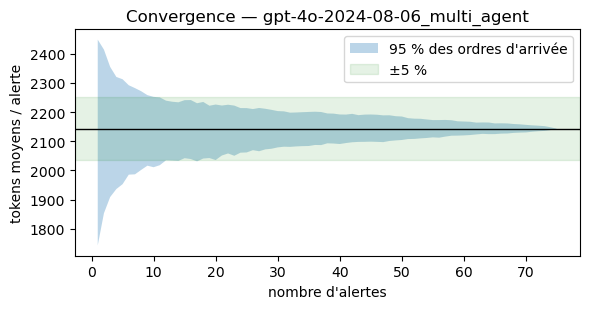

[gpt-4o-2024-08-06_single_agent] 75 alertes | CV inter-alertes des tokens = 12.0% | demi-largeur IC95 % obtenue = ±2.7%
   n requis pour ±10% sur la moyenne de tokens : 6
   n requis pour ±5% sur la moyenne de tokens : 23
   n requis pour ±3% sur la moyenne de tokens : 62
   exactitude répétition 1 = 100.0% [Wilson IC95 % : 95.1% – 100.0%] sur n = 75


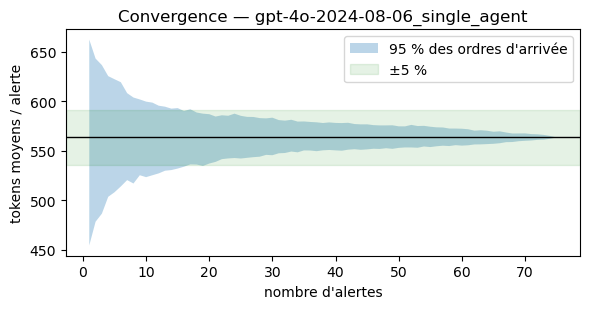

[gpt-4o-mini-2024-07-18_multi_agent] 75 alertes | CV inter-alertes des tokens = 15.1% | demi-largeur IC95 % obtenue = ±3.4%
   n requis pour ±10% sur la moyenne de tokens : 9
   n requis pour ±5% sur la moyenne de tokens : 35
   n requis pour ±3% sur la moyenne de tokens : 98
   exactitude répétition 1 = 97.3% [Wilson IC95 % : 90.8% – 99.3%] sur n = 75


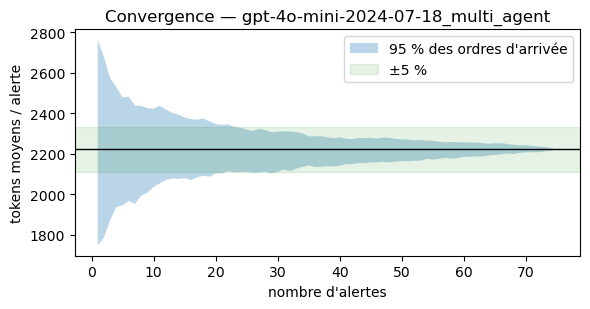

[gpt-4o-mini-2024-07-18_single_agent] 75 alertes | CV inter-alertes des tokens = 10.6% | demi-largeur IC95 % obtenue = ±2.4%
   n requis pour ±10% sur la moyenne de tokens : 5
   n requis pour ±5% sur la moyenne de tokens : 18
   n requis pour ±3% sur la moyenne de tokens : 48
   exactitude répétition 1 = 96.0% [Wilson IC95 % : 88.9% – 98.6%] sur n = 75


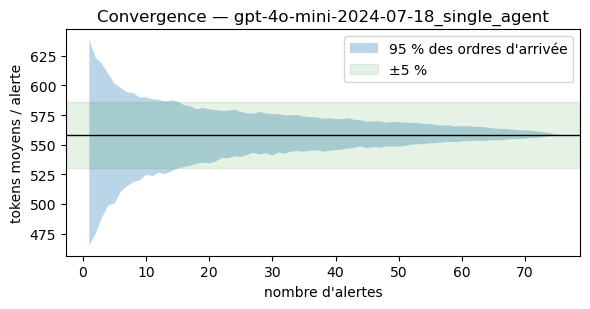

In [13]:
from math import sqrt
import matplotlib.pyplot as plt
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z*z/(2*n)) / (1 + z*z/n); h = z*sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return c - h, c + h

for m, g in per_alert.groupby("model"):
    t = g.groupby("alert_id")["total_tokens"].mean()          # 1 valeur par alerte (moyenne des répétitions)
    cv = t.std(ddof=1) / t.mean()
    print(f"[{m}] {len(t)} alertes | CV inter-alertes des tokens = {cv:.1%} | "
          f"demi-largeur IC95 % obtenue = ±{1.96*cv/sqrt(len(t)):.1%}")
    for prec in (0.10, 0.05, 0.03):
        print(f"   n requis pour ±{prec:.0%} sur la moyenne de tokens : {int(np.ceil((1.96*cv/prec)**2))}")
    if quality is not None:
        q1 = quality[quality.model == m].iloc[0]
        lo, hi = wilson(q1.TP + q1.TN, q1.n)
        print(f"   exactitude répétition 1 = {(q1.TP+q1.TN)/q1.n:.1%} [Wilson IC95 % : {lo:.1%} – {hi:.1%}] sur n = {q1.n}")
    perm = np.array([RNG.permutation(t.values).cumsum() / np.arange(1, len(t)+1) for _ in range(200)])
    fig, ax = plt.subplots(figsize=(6, 3.2)) if 'plt' in globals() else (None, None)
    if ax is None:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(6, 3.2))
    x = np.arange(1, len(t)+1)
    ax.fill_between(x, np.percentile(perm, 2.5, 0), np.percentile(perm, 97.5, 0), alpha=.3, label="95 % des ordres d'arrivée")
    ax.axhline(t.mean(), color="k", lw=1); ax.axhspan(t.mean()*0.95, t.mean()*1.05, color="g", alpha=.1, label="±5 %")
    ax.set_xlabel("nombre d'alertes"); ax.set_ylabel("tokens moyens / alerte"); ax.set_title(f"Convergence — {m}"); ax.legend()
    fig.tight_layout(); fig.savefig(OUT_DIR / f"fig_sample_size_{m}.png", dpi=300); plt.show()

## Baseline SOAR à règles
Un moteur de règles naïf (mots-clés → verdict + techniques) est appliqué aux mêmes alertes. Son temps CPU est **mesuré**, puis converti en énergie avec `SOAR_CPU_W`.


In [14]:
SOAR_RULES = {"mimikatz": "T1003", "lsass": "T1003", "powershell": "T1059", "encoded": "T1027",
              "failed login": "T1110", "brute": "T1110", "spraying": "T1110", "phishing": "T1566",
              "macro": "T1204", "exfil": "T1041", "ransom": "T1486", ".lock": "T1486"}

def soar_playbook(text):
    t = text.lower()
    tech = {v for k, v in SOAR_RULES.items() if k in t}
    return (1 if tech else 0), tech

N_LOOP = 2000
t0 = time.process_time()
for _ in range(N_LOOP):
    soar_out = [soar_playbook(a) for a in alerts_df["alert"]]
SOAR_CPU_S_PER_ALERT = (time.process_time() - t0) / (N_LOOP * len(alerts_df))
print(f"Temps CPU SOAR mesuré : {SOAR_CPU_S_PER_ALERT*1e6:.2f} µs/alerte "
      f"→ {SOAR_CPU_S_PER_ALERT*CENTRAL['SOAR_CPU_W']/3600*1e6:.4f} µWh/alerte (ESTIMÉ)")

soar_quality = None
if HAS_LABEL:
    y = alerts_df["label"].map(norm_label)
    mask = y.notna()
    soar_quality = cls_metrics(y[mask].astype(int), np.array([p for p, _ in soar_out])[mask.values])
    if HAS_MITRE:
        gt = alerts_df["mitre_gt"].map(techniques); pr = [t for _, t in soar_out]
        inter = sum(len(a & b) for a, b in zip(gt, pr))
        soar_quality["mitre_recall"] = inter / max(1, sum(map(len, gt)))
    print("Qualité SOAR (même vérité terrain) :", {k: round(v, 3) if isinstance(v, float) else v
                                                    for k, v in soar_quality.items()})

Temps CPU SOAR mesuré : 2.92 µs/alerte → 0.0243 µWh/alerte (ESTIMÉ)
Qualité SOAR (même vérité terrain) : {'n': 75, 'accuracy': 0.48, 'precision': 0.867, 'recall': 0.26, 'f1': 0.4, 'TP': 13, 'FP': 2, 'TN': 23, 'FN': 37, 'mitre_recall': 0.16}


## Énergie IA : deux estimateurs, PUE corrigé, réconciliation explicite

| Estimateur | Formule | Données mesurées utilisées |
|---|---|---|
| **E1 — par requête** | `n_requêtes × E_QUERY_WH` (PUE déjà inclus dans [6], **non réappliqué**) | nombre de requêtes |
| **E2 — par token** | `(tokens_sortie × e_out + tokens_entrée × e_out × PREFILL_RATIO) / 3600 × PUE` | tokens entrée/sortie |

Les deux méthodes de la v1 sont recalculées pour transparence. Elles servent au tableau de la lettre de réponse et **ne doivent plus être utilisées** :
- E1 multiplié par 1,2 : le PUE était compté deux fois ;
- E2 appliquant le coefficient de sortie à tous les tokens, entrée comprise.

**Pourquoi E1 et E2 divergent.** Le rapport E2/E1 se décompose exactement en un rapport de tailles de requête :

  `E2/E1 = (tokens effectifs observés par requête) / (tokens effectifs implicites dans le benchmark [6])`

E1 suppose que chaque requête du pipeline a la taille de la requête de référence du benchmark. E2 utilise les tokens réellement mesurés. L'écart n'est donc pas une erreur aléatoire : il mesure à quel point les requêtes du pipeline sont plus longues (ou plus courtes) que celles du benchmark.

**Modèle théorique à 12 requêtes.** Il est calculé à part et étiqueté **THÉORIQUE**. Il ne doit plus être comparé à E2 du pipeline mesuré pour annoncer un « accord à 4 % » (R2).

In [15]:
def pue_for(name, p):
    return 1.0 if PARAMS[name].get("includes_pue") else p["PUE"]

def e1_wh(n_queries, p, factor=1.0):
    """factor = rapport du benchmark du modèle à celui de REF_MODEL (Jegham T4, prompt court)."""
    return n_queries * p["E_QUERY_WH"] * factor * pue_for("E_QUERY_WH", p)

def e2_wh(prompt_tokens, completion_tokens, p):
    joules = completion_tokens * p["E_OUT_J_PER_TOKEN"] + prompt_tokens * p["E_OUT_J_PER_TOKEN"] * p["PREFILL_RATIO"]
    return joules / 3600 * pue_for("E_OUT_J_PER_TOKEN", p)

# E1-ajusté : même source que E1 (Jegham et al., Table 4), mis à l'échelle de la taille RÉELLE des requêtes.
# Ajustement exact E = a·tokens_entrée + b·tokens_sortie + c sur les 3 points publiés de CHAQUE modèle (PUE inclus) — voir §3.
pa = per_alert
pa["E1_Wh"] = e1_wh(pa["n_queries"], CENTRAL, pa["e1_factor"])
_fit = np.vstack(pa["api_model"].map(lambda m: JFIT.get(m, JFIT[REF_MODEL])))
pa["E1_scaled_Wh"] = _fit[:, 0] * pa["prompt_tokens"] + _fit[:, 1] * pa["completion_tokens"] + _fit[:, 2] * pa["n_queries"]
pa["E2_Wh"] = e2_wh(pa["prompt_tokens"], pa["completion_tokens"], CENTRAL)
pa["E2_over_E1"] = pa["E2_Wh"] / pa["E1_Wh"]
# Anciennes méthodes (v1) — pour la lettre de réponse uniquement
pa["v1_E1_double_PUE_Wh"] = pa["n_queries"] * CENTRAL["E_QUERY_WH"] * pa["e1_factor"] * 1.2
pa["v1_E2_all_tokens_as_output_Wh"] = pa["total_tokens"] * CENTRAL["E_OUT_J_PER_TOKEN"] / 3600 * CENTRAL["PUE"]

# ---- Décomposition analytique de l'écart ----
pue2 = pue_for("E_OUT_J_PER_TOKEN", CENTRAL)
recon_rows = []
for m, g in pa.groupby("model"):
    implied_tok_per_query = (CENTRAL["E_QUERY_WH"] * g["e1_factor"].iloc[0] * pue_for("E_QUERY_WH", CENTRAL) * 3600
                             / (CENTRAL["E_OUT_J_PER_TOKEN"] * pue2))
    obs_eff = ((g["completion_tokens"] + CENTRAL["PREFILL_RATIO"] * g["prompt_tokens"]) / g["n_queries"]).mean()
    recon_rows.append({
        "model": m, "nature": "ESTIMÉ (à partir de tokens MESURÉS)",
        "E1_Wh/alerte": g["E1_Wh"].mean(), "E1-ajusté (Jegham T4) Wh/alerte": g["E1_scaled_Wh"].mean(),
        "E2_Wh/alerte": g["E2_Wh"].mean(),
        "rapport E2/E1": g["E2_over_E1"].mean(),
        "tokens effectifs observés / requête": obs_eff,
        "tokens effectifs implicites dans [6] / requête": implied_tok_per_query,
        "rapport des tailles (= E2/E1)": obs_eff / implied_tok_per_query,
        "v1 : E1 × 1,2 (PUE compté 2×)": g["v1_E1_double_PUE_Wh"].mean(),
        "v1 : E2 tous tokens au tarif sortie": g["v1_E2_all_tokens_as_output_Wh"].mean()})
reconciliation = pd.DataFrame(recon_rows).set_index("model")
theoretical = pd.DataFrame([{
    "nature": "THÉORIQUE (non mesuré)", "n_requêtes": N_QUERIES_THEORETICAL,
    "E_Wh/alerte": N_QUERIES_THEORETICAL * CENTRAL["E_QUERY_WH"] * pue_for("E_QUERY_WH", CENTRAL)}],
    index=[f"Modèle théorique {N_QUERIES_THEORETICAL} requêtes"])
display(reconciliation.T.round(4))
display(theoretical.round(3))

# ---- Indépendance des estimateurs (R2) ----
s1, s2 = PARAMS["E_QUERY_WH"]["source"].strip(), PARAMS["E_OUT_J_PER_TOKEN"]["source"].strip()
if not s1 or not s2:
    verdict = "INDÉTERMINÉE : renseignez les deux sources."
elif s1 == s2:
    verdict = "NON indépendants (même source) → présenter E2 comme une variante de E1, pas comme une validation croisée."
else:
    verdict = "Indépendants quant aux coefficients (sources distinctes). Ils partagent les mêmes données mesurées (tokens/requêtes)."
print("Indépendance E1/E2 :", verdict)
print("→ Formulation recommandée : présenter [E1 ; E2] comme une FOURCHETTE d'estimation, et non comme un accord.")

model,gpt-4o-2024-08-06_multi_agent,gpt-4o-2024-08-06_single_agent,gpt-4o-mini-2024-07-18_multi_agent,gpt-4o-mini-2024-07-18_single_agent
nature,ESTIMÉ (à partir de tokens MESURÉS),ESTIMÉ (à partir de tokens MESURÉS),ESTIMÉ (à partir de tokens MESURÉS),ESTIMÉ (à partir de tokens MESURÉS)
E1_Wh/alerte,1.24,0.31,1.691442,0.422861
E1-ajusté (Jegham T4) Wh/alerte,1.585129,0.490995,2.01147,0.674326
E2_Wh/alerte,1.237546,0.417003,1.286506,0.411486
rapport E2/E1,0.998021,1.34517,0.760597,0.973101
tokens effectifs observés / requête,284.130456,382.961778,295.3712,377.895111
tokens effectifs implicites dans [6] / requête,284.693878,284.693878,388.341294,388.341294
rapport des tailles (= E2/E1),0.998021,1.34517,0.760597,0.973101
"v1 : E1 × 1,2 (PUE compté 2×)",1.488,0.372,2.02973,0.507433
v1 : E2 tous tokens au tarif sortie,2.333324,0.613543,2.419163,0.608026


,nature,n_requêtes,E_Wh/alerte
Modèle théorique 12 requêtes,THÉORIQUE (non mesuré),12,3.72


Indépendance E1/E2 : Indépendants quant aux coefficients (sources distinctes). Ils partagent les mêmes données mesurées (tokens/requêtes).
→ Formulation recommandée : présenter [E1 ; E2] comme une FOURCHETTE d'estimation, et non comme un accord.


## Comparaison des configurations : modèle × architecture
Ce tableau répond à « one model, one pipeline architecture ». Pour chaque configuration, il compare le coût (requêtes, tokens et énergie, MESURÉ puis ESTIMÉ) et la qualité (MESURÉ).



In [16]:
comp = per_alert.groupby("model").agg(
    n_requêtes=("n_queries", "mean"), tokens_entrée=("prompt_tokens", "mean"),
    tokens_sortie=("completion_tokens", "mean"), latence_s=("latency_s", "mean"),
    E1_Wh=("E1_Wh", "mean"), E1_ajusté_Wh=("E1_scaled_Wh", "mean"), E2_Wh=("E2_Wh", "mean"))
if quality is not None:
    qcols = [c for c in ["accuracy", "precision", "recall", "f1", "mitre_recall", "mitre_jaccard"] if c in quality]
    comp = comp.join(quality.groupby("model")[qcols].mean())
comp = comp.join(stab.rename("stabilité_verdict"))
comp.index.name = "configuration (modèle_architecture)"
display(comp.round(3))

# Surcoût du multi-agent par rapport à l'agent unique, à modèle égal
for api_model in MODELS:
    a, b = f"{api_model}_multi_agent", f"{api_model}_single_agent"
    if a in comp.index and b in comp.index:
        msg = (f"{api_model} : multi-agent / agent unique → énergie E2 ×{comp.loc[a,'E2_Wh']/comp.loc[b,'E2_Wh']:.2f}, "
               f"E1-ajusté ×{comp.loc[a,'E1_ajusté_Wh']/comp.loc[b,'E1_ajusté_Wh']:.2f}")
        if "f1" in comp:
            msg += f" | ΔF1 = {comp.loc[a,'f1']-comp.loc[b,'f1']:+.3f}"
        print(msg)
comp.to_csv(OUT_DIR / "configuration_comparison.csv")

,n_requêtes,tokens_entrée,tokens_sortie,latence_s,E1_Wh,E1_ajusté_Wh,E2_Wh,accuracy,precision,recall,f1,mitre_recall,mitre_jaccard,stabilité_verdict
configuration (modèle_architecture),,,,,,,,,,,,,,
gpt-4o-2024-08-06_multi_agent,4.0,1156.698,986.151,19.081,1.240,1.585,1.238,1.000,1.000,1.000,1.000,0.782,0.588,1.000
gpt-4o-2024-08-06_single_agent,1.0,207.467,355.991,3.830,0.310,0.491,0.417,1.000,1.000,1.000,1.000,0.747,0.617,1.000
gpt-4o-mini-2024-07-18_multi_agent,4.0,1195.627,1026.053,16.971,1.691,2.011,1.287,0.973,0.980,0.980,0.980,0.569,0.375,1.000
gpt-4o-mini-2024-07-18_single_agent,1.0,207.467,350.924,5.387,0.423,0.674,0.411,0.969,0.961,0.993,0.977,0.516,0.422,0.987


gpt-4o-2024-08-06 : multi-agent / agent unique → énergie E2 ×2.97, E1-ajusté ×3.23 | ΔF1 = +0.000
gpt-4o-mini-2024-07-18 : multi-agent / agent unique → énergie E2 ×3.13, E1-ajusté ×2.98 | ΔF1 = +0.003


##  Multi-agent vs agent unique : différences appariées avec IC 
Le manuscrit affirme que le pipeline à quatre agents consomme environ 3 fois plus d'énergie qu'un agent unique, pour un gain nul en F1 et modeste en rappel ATT&CK (+0,04 et +0,05). Pour savoir si ces écarts se distinguent de zéro, on les estime **de façon appariée** : les deux architectures traitent les **mêmes** 75 alertes avec le même modèle.

- Le bootstrap rééchantillonne les **alertes** ; chaque alerte tirée apporte ses 3 répétitions dans les deux architectures.
  
- Pour l'énergie et les tokens, on rapporte le **rapport** multi-agent / agent unique ; pour la qualité, la **différence** multi-agent − agent unique.
- `P(Δ>0)` est la part des répliques bootstrap où le multi-agent fait mieux (qualité) ou consomme plus (coût). Un IC qui contient 0 signifie que l'écart de qualité **n'est pas distinguable de zéro** sur ce jeu d'alertes.

In [17]:
N_BOOT_PAIRED = 2000
COST_COLS = ["total_tokens", "prompt_tokens", "completion_tokens", "latency_s", "E1_Wh", "E1_scaled_Wh", "E2_Wh"]
QUAL_METRICS = ["accuracy", "f1", "mitre_precision", "mitre_recall", "mitre_jaccard", "mitre_recall_macro_mal"]
paired_rows = []
for api_model in MODELS:
    a_cfg, b_cfg = f"{api_model}_multi_agent", f"{api_model}_single_agent"
    pa_m = per_alert[per_alert.model == a_cfg].groupby("alert_id")[COST_COLS].mean()
    pa_s = per_alert[per_alert.model == b_cfg].groupby("alert_id")[COST_COLS].mean()
    common = pa_m.index.intersection(pa_s.index)
    if len(common) == 0:
        continue
    A, B = pa_m.loc[common].to_numpy(float), pa_s.loc[common].to_numpy(float)
    idx = cluster_boot_idx(len(common), N_BOOT_PAIRED)
    ratio_boot = A[idx].mean(1) / B[idx].mean(1)            # (n_boot, n_cols) : rapport des moyennes
    point = A.mean(0) / B.mean(0)
    for j, c in enumerate(COST_COLS):
        paired_rows.append({"model": api_model, "quantity": c, "kind": "ratio multi/single (coût)",
                            "estimate": point[j], "ci95_low": np.percentile(ratio_boot[:, j], 2.5),
                            "ci95_high": np.percentile(ratio_boot[:, j], 97.5),
                            "P(Δ>0)": (ratio_boot[:, j] > 1).mean(), "n_alerts": len(common)})
    # ---- qualité : différences appariées
    if quality is not None:
        qa = q_long[q_long.model == a_cfg].reset_index(drop=True)
        qb = q_long[q_long.model == b_cfg].reset_index(drop=True)
        ids = sorted(set(qa.alert_id) & set(qb.alert_id))
        ia, ib = qa.groupby("alert_id").indices, qb.groupby("alert_id").indices

        def _metrics(q, ix):
            s = cls_metrics(q["y"].to_numpy(int)[ix], q["pred"].to_numpy(int)[ix])
            if "gt_set" in q:
                s.update(mitre_metrics([q["gt_set"].iat[i] for i in ix], [q["pred_mitre"].iat[i] for i in ix]))
            return s

        all_a = np.concatenate([ia[k] for k in ids]); all_b = np.concatenate([ib[k] for k in ids])
        pt_a, pt_b = _metrics(qa, all_a), _metrics(qb, all_b)
        boots = []
        for b in cluster_boot_idx(len(ids), N_BOOT_PAIRED):
            sa = _metrics(qa, np.concatenate([ia[ids[i]] for i in b]))
            sb = _metrics(qb, np.concatenate([ib[ids[i]] for i in b]))
            boots.append({k: sa.get(k, np.nan) - sb.get(k, np.nan) for k in QUAL_METRICS})
        bdf = pd.DataFrame(boots)
        for k in QUAL_METRICS:
            if k not in pt_a:
                continue
            paired_rows.append({"model": api_model, "quantity": k, "kind": "difference multi − single (qualité)",
                                "estimate": pt_a[k] - pt_b[k], "ci95_low": bdf[k].quantile(.025),
                                "ci95_high": bdf[k].quantile(.975), "P(Δ>0)": (bdf[k] > 0).mean(),
                                "n_alerts": len(ids)})
paired_arch = pd.DataFrame(paired_rows)
paired_arch["CI excludes no-effect"] = np.where(paired_arch["kind"].str.startswith("ratio"),
                                               (paired_arch.ci95_low > 1) | (paired_arch.ci95_high < 1),
                                               (paired_arch.ci95_low > 0) | (paired_arch.ci95_high < 0))
print("=== Multi-agent vs agent unique : estimations appariées, IC95 % (bootstrap groupé par alerte) ===")
display(paired_arch.round(3))
paired_arch.to_csv(OUT_DIR / "paired_architecture_comparison.csv", index=False)

# Phrases prêtes (anglais) pour la section IV-C
for api_model, g in paired_arch.groupby("model"):
    e2 = g[g.quantity == "E2_Wh"].iloc[0]
    msg = (f"[{api_model}] The four-agent pipeline used {e2.estimate:.2f}× the E2 energy of the single agent "
           f"(95% CI {e2.ci95_low:.2f}–{e2.ci95_high:.2f}, paired cluster bootstrap over {int(e2.n_alerts)} alerts)")
    for k, lab in [("f1", "verdict F1"), ("mitre_recall", "ATT&CK recall")]:
        r = g[g.quantity == k]
        if len(r):
            r = r.iloc[0]
            msg += (f"; difference in {lab} = {r.estimate:+.3f} (95% CI {r.ci95_low:+.3f} to {r.ci95_high:+.3f}"
                    f"{', not distinguishable from zero' if r.ci95_low <= 0 <= r.ci95_high else ''})")
    print(msg + ".")
PAIRED_ARCH_DONE = True

=== Multi-agent vs agent unique : estimations appariées, IC95 % (bootstrap groupé par alerte) ===


,model,quantity,kind,estimate,ci95_low,ci95_high,P(Δ>0),n_alerts,CI excludes no-effect
0,gpt-4o-2024-08-06,total_tokens,ratio multi/single (coût),3.803,3.752,3.853,1.000,75,True
1,gpt-4o-2024-08-06,prompt_tokens,ratio multi/single (coût),5.575,5.434,5.716,1.000,75,True
2,gpt-4o-2024-08-06,completion_tokens,ratio multi/single (coût),2.770,2.698,2.850,1.000,75,True
3,gpt-4o-2024-08-06,latency_s,ratio multi/single (coût),4.982,3.900,6.751,1.000,75,True
4,gpt-4o-2024-08-06,E1_Wh,ratio multi/single (coût),4.000,4.000,4.000,1.000,75,True
5,gpt-4o-2024-08-06,E1_scaled_Wh,ratio multi/single (coût),3.228,3.169,3.292,1.000,75,True
6,gpt-4o-2024-08-06,E2_Wh,ratio multi/single (coût),2.968,2.898,3.043,1.000,75,True
7,gpt-4o-2024-08-06,accuracy,difference multi − single (qualité),0.000,0.000,0.000,0.000,75,False
8,gpt-4o-2024-08-06,f1,difference multi − single (qualité),0.000,0.000,0.000,0.000,75,False
9,gpt-4o-2024-08-06,mitre_precision,difference multi − single (qualité),-0.067,-0.132,-0.001,0.020,75,True


[gpt-4o-2024-08-06] The four-agent pipeline used 2.97× the E2 energy of the single agent (95% CI 2.90–3.04, paired cluster bootstrap over 75 alerts); difference in verdict F1 = +0.000 (95% CI +0.000 to +0.000, not distinguishable from zero); difference in ATT&CK recall = +0.036 (95% CI -0.019 to +0.094, not distinguishable from zero).
[gpt-4o-mini-2024-07-18] The four-agent pipeline used 3.13× the E2 energy of the single agent (95% CI 3.07–3.19, paired cluster bootstrap over 75 alerts); difference in verdict F1 = +0.003 (95% CI -0.020 to +0.029, not distinguishable from zero); difference in ATT&CK recall = +0.053 (95% CI -0.014 to +0.123, not distinguishable from zero).


## Baseline humaine
Deux scénarios humains sont évalués, au lieu d'une valeur unique de 250 min :
- **triage L1** (10–45 min) : comparaison la plus conservatrice ;
- **investigation complète** (120–240 min, médiane 180 min).

`WS_ATTRIBUTION` < 1 représente la charge partagée : un analyste qui mène plusieurs investigations en parallèle n'attribue qu'une fraction de son poste à chaque alerte.


In [18]:
def human_wh(minutes, p):
    return minutes / 60 * p["WS_POWER_W"] * p["WS_ATTRIBUTION"]

HUMAN_MEASURED = None
if Path(HUMAN_MEASUREMENTS_PATH).exists():
    hm = pd.read_csv(HUMAN_MEASUREMENTS_PATH)
    hm["wh"] = hm["measured_wh"] if "measured_wh" in hm.columns else human_wh(hm["minutes"], CENTRAL)
    HUMAN_MEASURED = hm
    print("Mesures humaines chargées (MESURÉ) :")
    display(hm[["minutes", "wh"]].apply(describe).T.round(2))
else:
    print("Pas de mesures humaines → baseline = HYPOTHÈSE (plages du §3). Le signaler explicitement dans le manuscrit.")

for name in ["HUMAN_MIN_TRIAGE_L1", "HUMAN_MIN_FULL_INVEST", "HUMAN_REVIEW_MIN"]:
    lo, c, hi = (human_wh(PARAMS[name][k], CENTRAL) for k in ("low", "central", "high"))
    print(f"{name:24s}: {c:7.1f} Wh/alerte (plage {lo:.1f}–{hi:.1f}, à puissance et attribution centrales)")
# v3 (R2.2) : gabarit pour chronométrer des analystes sur LES MÊMES alertes (optionnel mais très utile)
_tmpl = alerts_df.sample(min(15, len(alerts_df)), random_state=SEED)[["alert_id", "alert"]]
_tmpl.assign(analyst_id="", level="L1|L2", minutes="", measured_wh="", started_utc="", notes="") \
     .to_csv(OUT_DIR / "human_measurements_template.csv", index=False)
print("Gabarit de mesure humaine →", OUT_DIR / "human_measurements_template.csv",
      "(remplir minutes ; measured_wh si wattmètre, puis renommer en human_measurements.csv)")
print(f"Rappel v1 : 250 min × 120 W = {250/60*120:.0f} Wh (valeur non justifiée, abandonnée)")

Pas de mesures humaines → baseline = HYPOTHÈSE (plages du §3). Le signaler explicitement dans le manuscrit.
HUMAN_MIN_TRIAGE_L1     :    40.0 Wh/alerte (plage 20.0–90.0, à puissance et attribution centrales)
HUMAN_MIN_FULL_INVEST   :   140.0 Wh/alerte (plage 60.0–480.0, à puissance et attribution centrales)
HUMAN_REVIEW_MIN        :    30.0 Wh/alerte (plage 10.0–60.0, à puissance et attribution centrales)
Gabarit de mesure humaine → outputs\run_final\human_measurements_template.csv (remplir minutes ; measured_wh si wattmètre, puis renommer en human_measurements.csv)
Rappel v1 : 250 min × 120 W = 500 Wh (valeur non justifiée, abandonnée)


## Scénarios comparés : énergie et CO₂ opérationnels par alerte

Périmètre : **émissions opérationnelles liées à l'électricité uniquement**. L'empreinte de cycle de vie (fabrication des GPU et des postes, réseau, eau) est **exclue** et doit être discutée comme une limite.

Le scénario **hybride** (IA + relecture humaine résiduelle) est le scénario réaliste : il répond à la remarque  « remaining human review ». 
Le scénario « IA seule » est une borne optimiste.

In [19]:
def scenarios(p, tok):
    """p : dict de paramètres (scalaires ou tableaux) ; tok : dict de tableaux mesurés par alerte. Renvoie (Wh, gCO2e)."""
    ci_c, ci_w = p["CI_CLOUD"] / 1000, p["CI_WORKSTATION"] / 1000
    ai1 = e1_wh(tok["n_queries"], p, tok.get("e1_factor", 1.0))
    ai2 = e2_wh(tok["prompt_tokens"], tok["completion_tokens"], p)
    cli = tok["latency_s"] / 3600 * p["CLIENT_W"]
    rev = human_wh(p["HUMAN_REVIEW_MIN"], p)
    soar = SOAR_CPU_S_PER_ALERT / 3600 * p["SOAR_CPU_W"]
    hl1, hfull = human_wh(p["HUMAN_MIN_TRIAGE_L1"], p), human_wh(p["HUMAN_MIN_FULL_INVEST"], p)
    energy = {  # (cloud_Wh, local_Wh)
        "Humain – triage L1":                  (0, hl1),
        "Humain – investigation complète":     (0, hfull),
        "IA seule (E1)":                       (ai1, cli),
        "IA seule (E2)":                       (ai2, cli),
        "Hybride IA (E1) + relecture humaine": (ai1, cli + rev),
        "Hybride IA (E2) + relecture humaine": (ai2, cli + rev),
        "SOAR à règles (baseline naïf)":       (0, soar),
    }
    if HUMAN_MEASURED is not None:
        energy["Humain (mesuré)"] = (0, tok["human_measured_wh"])
    wh = {k: c + l for k, (c, l) in energy.items()}
    co2 = {k: c * ci_c + l * ci_w for k, (c, l) in energy.items()}
    return wh, co2


def tok_arrays(df, idx=None):
    d = df if idx is None else df.iloc[idx]
    t = {c: d[c].to_numpy(float) for c in ["n_queries", "prompt_tokens", "completion_tokens", "latency_s", "e1_factor"]}
    if HUMAN_MEASURED is not None:
        hw = HUMAN_MEASURED["wh"].to_numpy(float)
        t["human_measured_wh"] = hw.mean() if idx is None else RNG.choice(hw, len(d))
    return t


NATURE = {"Humain (mesuré)": "MESURÉ", "SOAR à règles (baseline naïf)": "ESTIMÉ (CPU mesuré)"}
central_rows = []
for m, g in per_alert.groupby("model"):
    wh, co2 = scenarios(CENTRAL, tok_arrays(g))
    for k in wh:
        nat = NATURE.get(k, "HYPOTHÈSE" if k.startswith("Humain") else "ESTIMÉ (tokens MESURÉS)")
        central_rows.append({"model": m, "scénario": k, "nature": nat,
                             "Wh/alerte": np.mean(wh[k]), "gCO2e/alerte": np.mean(co2[k])})
central_table = pd.DataFrame(central_rows)
display(central_table.style.format({"Wh/alerte": "{:.4g}", "gCO2e/alerte": "{:.4g}"}))

,model,scénario,nature,Wh/alerte,gCO2e/alerte
0,gpt-4o-2024-08-06_multi_agent,Humain – triage L1,HYPOTHÈSE,40,17.4
1,gpt-4o-2024-08-06_multi_agent,Humain – investigation complète,HYPOTHÈSE,140,60.9
2,gpt-4o-2024-08-06_multi_agent,IA seule (E1),ESTIMÉ (tokens MESURÉS),1.399,0.5032
3,gpt-4o-2024-08-06_multi_agent,IA seule (E2),ESTIMÉ (tokens MESURÉS),1.397,0.5023
4,gpt-4o-2024-08-06_multi_agent,Hybride IA (E1) + relecture humaine,ESTIMÉ (tokens MESURÉS),31.4,13.55
5,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,ESTIMÉ (tokens MESURÉS),31.4,13.55
6,gpt-4o-2024-08-06_multi_agent,SOAR à règles (baseline naïf),ESTIMÉ (CPU mesuré),2.431e-08,1.057e-08
7,gpt-4o-2024-08-06_single_agent,Humain – triage L1,HYPOTHÈSE,40,17.4
8,gpt-4o-2024-08-06_single_agent,Humain – investigation complète,HYPOTHÈSE,140,60.9
9,gpt-4o-2024-08-06_single_agent,IA seule (E1),ESTIMÉ (tokens MESURÉS),0.3419,0.1224


## Propagation de l'incertitude : Monte Carlo et bootstrap 
Chaque tirage combine deux sources d'aléa :
- tous les paramètres du §3 sont tirés selon une loi triangulaire (`low`, `central`, `high`) ;
- une alerte mesurée est tirée au hasard (bootstrap), ce qui couvre la variabilité entre alertes et entre répétitions.

Le résultat est une médiane avec un intervalle à 95 % pour chaque scénario et pour chaque réduction relative. `P(réduction > 0)` indique la probabilité que l'IA émette moins que l'humain sous les hypothèses retenues.

In [20]:
N_MC = 20_000

def sample_params(n):
    out = {}
    for k, v in PARAMS.items():
        lo, c, hi = v["low"], v["central"], v["high"]
        out[k] = np.full(n, c, float) if lo == hi else RNG.triangular(lo, c, hi, n)
    return out

def pct(x):
    return pd.Series({"p2.5": np.percentile(x, 2.5), "médiane": np.median(x), "p97.5": np.percentile(x, 97.5)})

COMPARISONS = [  # (IA, humain)
    ("Hybride IA (E2) + relecture humaine", "Humain – triage L1"),
    ("Hybride IA (E1) + relecture humaine", "Humain – triage L1"),
    ("Hybride IA (E2) + relecture humaine", "Humain – investigation complète"),
    ("IA seule (E2)", "Humain – investigation complète"),
    ("IA seule (E1)", "Humain – investigation complète"),
]
if HUMAN_MEASURED is not None:
    COMPARISONS.insert(0, ("Hybride IA (E2) + relecture humaine", "Humain (mesuré)"))

mc_co2, mc_red, mc_annual, MC_DRAWS = [], [], [], {}
for m, g in per_alert.groupby("model"):
    p = sample_params(N_MC)
    idx = RNG.integers(0, len(g), N_MC)
    wh, co2 = scenarios(p, tok_arrays(g, idx))
    MC_DRAWS[m] = co2
    for k, v in co2.items():
        mc_co2.append({"model": m, "scénario": k, **pct(v)})
    for ai, hu in COMPARISONS:
        red = 100 * (1 - co2[ai] / co2[hu])
        mc_red.append({"model": m, "IA": ai, "référence": hu, **pct(red), "P(réduction>0)": (red > 0).mean()})
        saved_kg = p["ALERTS_PER_YEAR"] * (co2[hu] - co2[ai]) / 1000
        mc_annual.append({"model": m, "IA": ai, "référence": hu, "nature": "EXTRAPOLÉ", **pct(saved_kg)})

mc_co2 = pd.DataFrame(mc_co2)
mc_red = pd.DataFrame(mc_red)
mc_annual = pd.DataFrame(mc_annual)
print("=== gCO2e par alerte (opérationnel, électricité) : médiane [IC95 %] ===")
display(mc_co2.round(5))
print("=== Réduction relative (%) : médiane [IC95 %] ===")
display(mc_red.round(2))

=== gCO2e par alerte (opérationnel, électricité) : médiane [IC95 %] ===


,model,scénario,p2.5,médiane,p97.5
0,gpt-4o-2024-08-06_multi_agent,Humain – triage L1,4.87823,18.81453,51.12563
1,gpt-4o-2024-08-06_multi_agent,Humain – investigation complète,19.09400,81.12807,253.98338
2,gpt-4o-2024-08-06_multi_agent,IA seule (E1),0.31376,0.53828,0.88636
3,gpt-4o-2024-08-06_multi_agent,IA seule (E2),0.23061,0.45424,0.73888
4,gpt-4o-2024-08-06_multi_agent,Hybride IA (E1) + relecture humaine,3.71220,13.08286,34.78638
5,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,3.62032,12.98802,34.72765
6,gpt-4o-2024-08-06_multi_agent,SOAR à règles (baseline naïf),0.00000,0.00000,0.00000
7,gpt-4o-2024-08-06_single_agent,Humain – triage L1,4.75528,18.61847,50.34131
8,gpt-4o-2024-08-06_single_agent,Humain – investigation complète,18.88662,79.55270,253.46121
9,gpt-4o-2024-08-06_single_agent,IA seule (E1),0.07800,0.13464,0.21303


=== Réduction relative (%) : médiane [IC95 %] ===


,model,IA,référence,p2.5,médiane,p97.5,P(réduction>0)
0,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,Humain – triage L1,-59.82,30.40,71.25,0.79
1,gpt-4o-2024-08-06_multi_agent,Hybride IA (E1) + relecture humaine,Humain – triage L1,-61.20,29.77,70.96,0.78
2,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,Humain – investigation complète,55.68,84.17,94.17,1.00
3,gpt-4o-2024-08-06_multi_agent,IA seule (E2),Humain – investigation complète,97.43,99.45,99.84,1.00
4,gpt-4o-2024-08-06_multi_agent,IA seule (E1),Humain – investigation complète,96.92,99.34,99.81,1.00
5,gpt-4o-2024-08-06_single_agent,Hybride IA (E2) + relecture humaine,Humain – triage L1,-57.04,32.02,73.01,0.81
6,gpt-4o-2024-08-06_single_agent,Hybride IA (E1) + relecture humaine,Humain – triage L1,-56.96,32.07,73.11,0.81
7,gpt-4o-2024-08-06_single_agent,Hybride IA (E2) + relecture humaine,Humain – investigation complète,57.34,84.50,94.55,1.00
8,gpt-4o-2024-08-06_single_agent,IA seule (E2),Humain – investigation complète,99.20,99.82,99.95,1.00
9,gpt-4o-2024-08-06_single_agent,IA seule (E1),Humain – investigation complète,99.27,99.83,99.95,1.00


## Projection du cycle de vie : carbone incorporé et eau

Le périmètre principal reste l'électricité opérationnelle. 

**Carbone incorporé (fabrication).**
- Côté IA, il est réparti au prorata de l'énergie servie : `EMB_SERVER_KG / (SERVER_POWER_KW × durée de vie × taux d'utilisation)` donne des gCO₂e par Wh d'inférence, multipliés par l'énergie IA estimée de l'alerte.
- Côté humain, il est réparti au prorata du temps d'usage : `WS_EMB_KG / (WS_LIFETIME_Y × WS_HOURS_PER_YEAR)` donne des gCO₂e par heure de poste, multipliés par la durée de traitement et `WS_ATTRIBUTION`.

**Eau.**
- Côté cloud : énergie × (WUE sur site + EWIF hors site).
- Côté poste : énergie × EWIF. La climatisation des bureaux est exclue.

Simplifications à mentionner :
- l'énergie IA utilisée inclut le PUE, ce qui surestime légèrement la part incorporée et l'eau sur site de l'IA (conservateur pour l'IA) ;
- le carbone incorporé du réseau, du stockage et de l'ordinateur client est négligé.

Tous les paramètres sont tirés dans le même Monte Carlo que le §15.

In [21]:
def lifecycle(p, tok):
    """Renvoie (incorporé gCO2e, eau L) par alerte et par scénario. Mêmes conventions que scenarios()."""
    g_per_wh_ai = p["EMB_SERVER_KG"] * 1000 / (p["SERVER_POWER_KW"] * 1000 * p["HW_LIFETIME_Y"] * 8760 * p["SERVER_UTIL"])
    g_per_h_ws = p["WS_EMB_KG"] * 1000 / (p["WS_LIFETIME_Y"] * p["WS_HOURS_PER_YEAR"])
    ai1 = e1_wh(tok["n_queries"], p, tok.get("e1_factor", 1.0))
    ai2 = e2_wh(tok["prompt_tokens"], tok["completion_tokens"], p)
    cli = tok["latency_s"] / 3600 * p["CLIENT_W"]
    def ws_h(minutes):
        return minutes / 60 * p["WS_ATTRIBUTION"]
    water_cloud = (p["WUE_ONSITE_L_PER_KWH"] + p["EWIF_L_PER_KWH"]) / 1000      # L par Wh
    water_local = p["EWIF_L_PER_KWH"] / 1000
    rev = p["HUMAN_REVIEW_MIN"]
    defs = {  # (Wh cloud, Wh local, heures de poste attribuées)
        "Humain – triage L1":                  (0, human_wh(p["HUMAN_MIN_TRIAGE_L1"], p), ws_h(p["HUMAN_MIN_TRIAGE_L1"])),
        "Humain – investigation complète":     (0, human_wh(p["HUMAN_MIN_FULL_INVEST"], p), ws_h(p["HUMAN_MIN_FULL_INVEST"])),
        "IA seule (E1)":                       (ai1, cli, 0),
        "IA seule (E2)":                       (ai2, cli, 0),
        "Hybride IA (E1) + relecture humaine": (ai1, cli + human_wh(rev, p), ws_h(rev)),
        "Hybride IA (E2) + relecture humaine": (ai2, cli + human_wh(rev, p), ws_h(rev)),
    }
    emb = {k: c * g_per_wh_ai + h * g_per_h_ws for k, (c, l, h) in defs.items()}
    water = {k: c * water_cloud + l * water_local for k, (c, l, h) in defs.items()}
    return emb, water


lc_rows, lc_red = [], []
for m, g in per_alert.groupby("model"):
    p = sample_params(N_MC)
    idx = RNG.integers(0, len(g), N_MC)
    tok = tok_arrays(g, idx)
    _, co2 = scenarios(p, tok)
    emb, water = lifecycle(p, tok)
    for k in emb:
        tot = co2[k] + emb[k]
        lc_rows.append({"model": m, "scénario": k, "nature": "PROJECTION",
                        "opérationnel g (méd.)": np.median(co2[k]),
                        "incorporé g (méd.)": np.median(emb[k]), "incorporé g p2.5": np.percentile(emb[k], 2.5),
                        "incorporé g p97.5": np.percentile(emb[k], 97.5),
                        "part incorporée % (méd.)": np.median(100 * emb[k] / tot),
                        "total g (méd.)": np.median(tot), "total g p2.5": np.percentile(tot, 2.5),
                        "total g p97.5": np.percentile(tot, 97.5),
                        "eau L (méd.)": np.median(water[k]), "eau L p2.5": np.percentile(water[k], 2.5),
                        "eau L p97.5": np.percentile(water[k], 97.5)})
    for ai, hu in COMPARISONS:
        if ai in emb and hu in emb:
            red_tot = 100 * (1 - (co2[ai] + emb[ai]) / (co2[hu] + emb[hu]))
            red_w = 100 * (1 - water[ai] / water[hu])
            lc_red.append({"model": m, "IA": ai, "référence": hu, "nature": "PROJECTION",
                           "réduction CO2 cycle de vie % (méd.)": np.median(red_tot),
                           "p2.5": np.percentile(red_tot, 2.5), "p97.5": np.percentile(red_tot, 97.5),
                           "P(réduction>0)": (red_tot > 0).mean(),
                           "réduction eau % (méd.)": np.median(red_w), "eau p2.5": np.percentile(red_w, 2.5),
                           "eau p97.5": np.percentile(red_w, 97.5)})
lifecycle_mc = pd.DataFrame(lc_rows)
lifecycle_red = pd.DataFrame(lc_red)
print("=== Projection cycle de vie par alerte (opérationnel + incorporé ; eau) — PROJECTION ===")
display(lifecycle_mc.round(4))
print("=== Réductions en incluant le carbone incorporé, et réduction de l'eau ===")
display(lifecycle_red.round(2))
lifecycle_mc.to_csv(OUT_DIR / "lifecycle_mc.csv", index=False)
lifecycle_red.to_csv(OUT_DIR / "lifecycle_reductions.csv", index=False)
LIFECYCLE_DONE = True

=== Projection cycle de vie par alerte (opérationnel + incorporé ; eau) — PROJECTION ===


,model,scénario,nature,opérationnel g (méd.),incorporé g (méd.),incorporé g p2.5,incorporé g p97.5,part incorporée % (méd.),total g (méd.),total g p2.5,total g p97.5,eau L (méd.),eau L p2.5,eau L p97.5
0,gpt-4o-2024-08-06_multi_agent,Humain – triage L1,PROJECTION,18.4825,12.6529,5.5131,27.1087,40.2766,31.7583,12.7071,72.3560,0.1314,0.0451,0.3362
1,gpt-4o-2024-08-06_multi_agent,Humain – investigation complète,PROJECTION,80.9677,56.0599,19.8634,137.6586,40.2766,140.0683,47.2641,365.0711,0.5751,0.1716,1.6566
2,gpt-4o-2024-08-06_multi_agent,IA seule (E1),PROJECTION,0.5367,0.0394,0.0163,0.0936,6.8383,0.5792,0.3367,0.9408,0.0048,0.0023,0.0089
3,gpt-4o-2024-08-06_multi_agent,IA seule (E2),PROJECTION,0.4533,0.0322,0.0123,0.0757,6.6647,0.4883,0.2503,0.7805,0.0040,0.0017,0.0074
4,gpt-4o-2024-08-06_multi_agent,Hybride IA (E1) + relecture humaine,PROJECTION,12.9655,8.5714,3.3878,18.1776,39.2726,21.8925,8.3232,48.6474,0.0931,0.0314,0.2260
5,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,PROJECTION,12.8913,8.5625,3.3775,18.1721,39.4535,21.8112,8.2346,48.5431,0.0922,0.0310,0.2251
6,gpt-4o-2024-08-06_single_agent,Humain – triage L1,PROJECTION,18.6066,12.6660,5.5131,27.1480,40.2043,31.8403,12.9129,71.9110,0.1317,0.0449,0.3333
7,gpt-4o-2024-08-06_single_agent,Humain – investigation complète,PROJECTION,80.6486,55.8690,19.7204,136.5954,40.2043,140.1006,46.0589,360.2047,0.5737,0.1711,1.6442
8,gpt-4o-2024-08-06_single_agent,IA seule (E1),PROJECTION,0.1340,0.0099,0.0041,0.0236,6.8772,0.1446,0.0845,0.2307,0.0012,0.0006,0.0022
9,gpt-4o-2024-08-06_single_agent,IA seule (E2),PROJECTION,0.1434,0.0106,0.0039,0.0261,6.9315,0.1548,0.0746,0.2628,0.0013,0.0005,0.0025


=== Réductions en incluant le carbone incorporé, et réduction de l'eau ===


,model,IA,référence,nature,réduction CO2 cycle de vie % (méd.),p2.5,p97.5,P(réduction>0),réduction eau % (méd.),eau p2.5,eau p97.5
0,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,Humain – triage L1,PROJECTION,31.42,-56.23,72.29,0.80,29.73,-58.92,71.19
1,gpt-4o-2024-08-06_multi_agent,Hybride IA (E1) + relecture humaine,Humain – triage L1,PROJECTION,31.14,-56.79,72.03,0.80,29.12,-60.00,70.68
2,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,Humain – investigation complète,PROJECTION,84.59,56.51,94.39,1.00,84.22,55.68,94.17
3,gpt-4o-2024-08-06_multi_agent,IA seule (E2),Humain – investigation complète,PROJECTION,99.66,98.84,99.89,1.00,99.32,97.75,99.77
4,gpt-4o-2024-08-06_multi_agent,IA seule (E1),Humain – investigation complète,PROJECTION,99.59,98.62,99.86,1.00,99.17,97.31,99.71
5,gpt-4o-2024-08-06_single_agent,Hybride IA (E2) + relecture humaine,Humain – triage L1,PROJECTION,32.41,-53.40,73.69,0.81,31.89,-54.21,73.23
6,gpt-4o-2024-08-06_single_agent,Hybride IA (E1) + relecture humaine,Humain – triage L1,PROJECTION,32.43,-53.31,73.75,0.81,31.94,-54.18,73.33
7,gpt-4o-2024-08-06_single_agent,Hybride IA (E2) + relecture humaine,Humain – investigation complète,PROJECTION,84.76,56.98,94.48,1.00,84.64,56.73,94.40
8,gpt-4o-2024-08-06_single_agent,IA seule (E2),Humain – investigation complète,PROJECTION,99.89,99.63,99.97,1.00,99.78,99.28,99.93
9,gpt-4o-2024-08-06_single_agent,IA seule (E1),Humain – investigation complète,PROJECTION,99.90,99.67,99.96,1.00,99.79,99.34,99.93


## Seuil de rentabilité en temps humain

Si le temps humain réel dépasse ce seuil, la conclusion tient quelle que soit la valeur exacte.
- **IA seule** : seuil = CO₂ IA / CO₂ d'une minute de poste.
- **Hybride** : le seuil dépasse forcément le temps de relecture (`HUMAN_REVIEW_MIN`), puisque l'hybride contient déjà ce temps humain.

Le calcul est fait avec tous les paramètres tirés au sort (Monte Carlo), plus une courbe centrale.

,model,scénario IA,nature,seuil minutes (méd.),p2.5,p97.5,P(seuil < 20 min L1),P(seuil < 70 min)
0,gpt-4o-2024-08-06_multi_agent,IA seule (E1),ESTIMÉ,0.692,0.271,2.487,1.000,1.0
1,gpt-4o-2024-08-06_multi_agent,IA seule (E2),ESTIMÉ,0.575,0.214,2.067,1.000,1.0
2,gpt-4o-2024-08-06_multi_agent,Hybride IA (E1) + relecture humaine,ESTIMÉ,17.191,8.246,27.817,0.679,1.0
3,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,ESTIMÉ,17.043,8.163,27.647,0.688,1.0
4,gpt-4o-2024-08-06_single_agent,IA seule (E1),ESTIMÉ,0.172,0.069,0.596,1.000,1.0
5,gpt-4o-2024-08-06_single_agent,IA seule (E2),ESTIMÉ,0.181,0.065,0.654,1.000,1.0
6,gpt-4o-2024-08-06_single_agent,Hybride IA (E1) + relecture humaine,ESTIMÉ,16.428,7.674,27.024,0.726,1.0
7,gpt-4o-2024-08-06_single_agent,Hybride IA (E2) + relecture humaine,ESTIMÉ,16.445,7.684,27.043,0.725,1.0
8,gpt-4o-mini-2024-07-18_multi_agent,IA seule (E1),ESTIMÉ,0.930,0.358,3.306,1.000,1.0
9,gpt-4o-mini-2024-07-18_multi_agent,IA seule (E2),ESTIMÉ,0.599,0.220,2.117,1.000,1.0


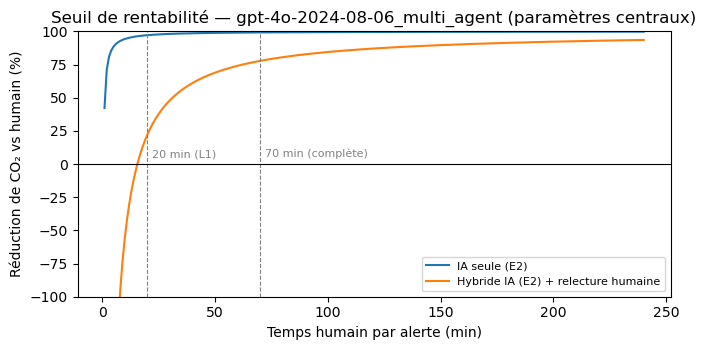

In [22]:
def breakeven_minutes(p, tok):
    """Minutes humaines/alerte au-delà desquelles l'humain émet plus que l'IA (CO2 opérationnel)."""
    _, co2 = scenarios(p, tok)
    g_per_min = p["WS_POWER_W"] * p["WS_ATTRIBUTION"] / 60 * p["CI_WORKSTATION"] / 1000   # gCO2e par minute de poste
    return {k: co2[k] / g_per_min for k in ["IA seule (E1)", "IA seule (E2)",
                                             "Hybride IA (E1) + relecture humaine", "Hybride IA (E2) + relecture humaine"]}

be_rows = []
for m, g in per_alert.groupby("model"):
    p = sample_params(N_MC)
    be = breakeven_minutes(p, tok_arrays(g, RNG.integers(0, len(g), N_MC)))
    for k, v in be.items():
        be_rows.append({"model": m, "scénario IA": k, "nature": "ESTIMÉ",
                        "seuil minutes (méd.)": np.median(v), "p2.5": np.percentile(v, 2.5), "p97.5": np.percentile(v, 97.5),
                        "P(seuil < 20 min L1)": (v < 20).mean(), "P(seuil < 70 min)": (v < 70).mean()})
breakeven = pd.DataFrame(be_rows)
display(breakeven.round(3))
breakeven.to_csv(OUT_DIR / "breakeven_human_minutes.csv", index=False)

# Courbe centrale : réduction (%) en fonction du temps humain, configuration de référence
REF_CONFIG = f"{MODELS[0]}_{ARCHITECTURES[0]}"
_tok = tok_arrays(per_alert[per_alert.model == REF_CONFIG])
mins = np.arange(1, 241)
curves = {}
for k in ["IA seule (E2)", "Hybride IA (E2) + relecture humaine"]:
    vals = []
    for mm in mins:
        _, co2 = scenarios({**CENTRAL, "HUMAN_MIN_TRIAGE_L1": mm}, _tok)
        vals.append(100 * (1 - np.mean(co2[k]) / np.mean(co2["Humain – triage L1"])))
    curves[k] = vals
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, v in curves.items():
    ax.plot(mins, v, label=k)
for x, lab in [(20, "20 min (L1)"), (70, "70 min (complète)")]:
    ax.axvline(x, ls="--", lw=.8, color="grey"); ax.text(x + 2, 5, lab, fontsize=8, color="grey")
ax.axhline(0, color="k", lw=.8)
ax.set_xlabel("Temps humain par alerte (min)"); ax.set_ylabel("Réduction de CO₂ vs humain (%)")
ax.set_title(f"Seuil de rentabilité — {REF_CONFIG} (paramètres centraux)"); ax.set_ylim(-100, 100); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "fig_breakeven_minutes.png", dpi=300); plt.show()
BREAKEVEN_DONE = True

## Analyse de sensibilité un-à-un : tornado
Indicateur étudié : la réduction de CO₂ du scénario **hybride (E2)** par rapport au **triage humain L1**, soit la comparaison la plus défavorable à l'IA. Chaque paramètre est placé à sa borne basse puis haute, les autres restant à leur valeur centrale.

Configuration de référence pour le tornado : gpt-4o-2024-08-06_multi_agent
Réduction centrale (Hybride IA (E2) + relecture humaine vs Humain – triage L1) : 22.11 %


,paramètre,réduction @low,réduction @high,amplitude
8,HUMAN_REVIEW_MIN,72.113,-52.887,125.000
7,HUMAN_MIN_TRIAGE_L1,-55.774,65.384,121.157
4,CI_WORKSTATION,2.945,23.159,20.213
5,WS_POWER_W,20.051,23.614,3.563
6,WS_ATTRIBUTION,19.226,22.113,2.887
0,E_OUT_J_PER_TOKEN,23.891,21.758,2.134
3,CI_CLOUD,22.824,21.509,1.316
2,PUE,22.180,21.180,1.000
9,CLIENT_W,22.378,21.716,0.663
1,PREFILL_RATIO,22.316,21.682,0.633


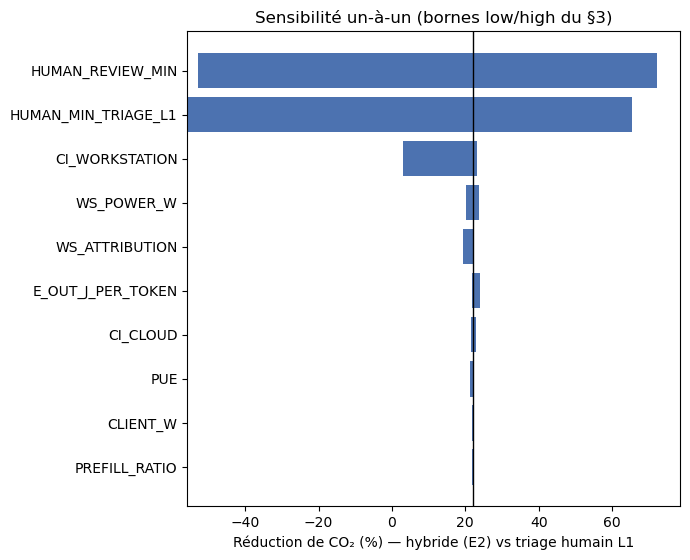

In [23]:
import matplotlib.pyplot as plt

AI_REF, HU_REF = "Hybride IA (E2) + relecture humaine", "Humain – triage L1"
REF_CONFIG = f"{MODELS[0]}_{ARCHITECTURES[0]}"
_ref = per_alert[per_alert["model"] == REF_CONFIG]
tok_c = {c: _ref[c].mean() for c in ["n_queries", "prompt_tokens", "completion_tokens", "latency_s", "e1_factor"]}
print("Configuration de référence pour le tornado :", REF_CONFIG)
if HUMAN_MEASURED is not None:
    tok_c["human_measured_wh"] = HUMAN_MEASURED["wh"].mean()

def reduction(p):
    _, co2 = scenarios(p, tok_c)
    return 100 * (1 - co2[AI_REF] / co2[HU_REF])

base = reduction(CENTRAL)
tornado = []
for k, v in PARAMS.items():
    if v["low"] == v["high"]:
        continue
    lo, hi = reduction({**CENTRAL, k: v["low"]}), reduction({**CENTRAL, k: v["high"]})
    if abs(hi - lo) > 1e-9:
        tornado.append({"paramètre": k, "réduction @low": lo, "réduction @high": hi, "amplitude": abs(hi - lo)})
tornado = pd.DataFrame(tornado).sort_values("amplitude")
print(f"Réduction centrale ({AI_REF} vs {HU_REF}) : {base:.2f} %")
display(tornado.sort_values("amplitude", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(7, 0.45 * len(tornado) + 1.2))
for i, r in enumerate(tornado.itertuples()):
    a, b = sorted([r[2], r[3]])
    ax.barh(i, b - a, left=a, color="#4C72B0")
ax.axvline(base, color="k", lw=1)
ax.set_yticks(range(len(tornado)), tornado["paramètre"])
ax.set_xlabel("Réduction de CO₂ (%) — hybride (E2) vs triage humain L1")
ax.set_title("Sensibilité un-à-un (bornes low/high du §3)")
fig.tight_layout(); fig.savefig(OUT_DIR / "fig_tornado.png", dpi=300); plt.show()

## Scénarios de réseau électrique : cloud et poste séparés
Les intensités ci-dessous sont des **niveaux génériques** (réseau bas carbone → réseau fortement carboné). Remplacez-les par les valeurs sourcées des pays concernés : région du datacenter et pays du SOC.

In [24]:
GRID_LEVELS = {"bas carbone": 50, "intermédiaire": 250, "Azure (350)": 350, "moyenne mondiale IEA 2025 (435)": 435,
               "Maroc (536)": 536, "fortement carboné": 750}
grid_rows = []
for m, g in per_alert.groupby("model"):
    tok = tok_arrays(g)
    for cn, cc in GRID_LEVELS.items():
        for wn, wc in GRID_LEVELS.items():
            _, co2 = scenarios({**CENTRAL, "CI_CLOUD": cc, "CI_WORKSTATION": wc}, tok)
            grid_rows.append({"model": m, "réseau cloud": cn, "réseau SOC": wn,
                              "hybride E2 (g)": np.mean(co2[AI_REF]), "humain L1 (g)": np.mean(co2[HU_REF]),
                              "réduction %": 100 * (1 - np.mean(co2[AI_REF]) / np.mean(co2[HU_REF]))})
grid = pd.DataFrame(grid_rows)
display(grid.pivot_table(index=["model", "réseau cloud"], columns="réseau SOC", values="réduction %").round(1))

réseau SOC                                                           Azure (350)  \
model                               réseau cloud                                   
gpt-4o-2024-08-06_multi_agent       Azure (350)                             21.5   
                                    Maroc (536)                             19.9   
                                    bas carbone                             24.2   
                                    fortement carboné                       18.0   
                                    intermédiaire                           22.4   
                                    moyenne mondiale IEA 2025 (435)         20.8   
gpt-4o-2024-08-06_single_agent      Azure (350)                             23.9   
                                    Maroc (536)                             23.3   
                                    bas carbone                             24.8   
                                    fortement carboné                       22.7   
                                    intermédiaire                           24.2   
                                    moyenne mondiale IEA 2025 (435)         23.6   
gpt-4o-mini-2024-07-18_multi_agent  Azure (350)                             21.4   
                                    Maroc (536)                             19.7   
                                    bas carbone                             24.2   
                                    fortement carboné                       17.8   
                                    intermédiaire                           22.3   
                                    moyenne mondiale IEA 2025 (435)         20.6   
gpt-4o-mini-2024-07-18_single_agent Azure (350)                             23.9   
                                    Maroc (536)                             23.3   
                                    bas carbone                             24.7   
                                    fortement carboné                       22.7   
                                    intermédiaire                           24.2   
                                    moyenne mondiale IEA 2025 (435)         23.6   

réseau SOC                                                           Maroc (536)  \
model                               réseau cloud                                   
gpt-4o-2024-08-06_multi_agent       Azure (350)                             22.6   
                                    Maroc (536)                             21.5   
                                    bas carbone                             24.3   
                                    fortement carboné                       20.3   
                                    intermédiaire                           23.2   
                                    moyenne mondiale IEA 2025 (435)         22.1   
gpt-4o-2024-08-06_single_agent      Azure (350)                             24.2   
                                    Maroc (536)                             23.9   
                                    bas carbone                             24.8   
                                    fortement carboné                       23.5   
                                    intermédiaire                           24.4   
                                    moyenne mondiale IEA 2025 (435)         24.1   
gpt-4o-mini-2024-07-18_multi_agent  Azure (350)                             22.5   
                                    Maroc (536)                             21.4   
                                    bas carbone                             24.3   
                                    fortement carboné                       20.1   
                                    intermédiaire                           23.1   
                                    moyenne mondiale IEA 2025 (435)         22.0   
gpt-4o-mini-2024-07-18_single_agent Azure (350)                             24.2   
                                    Maroc (536)    

## Économies annuelles (EXTRAPOLÉ)
Extrapolation : `ALERTS_PER_YEAR × (CO₂ humain − CO₂ IA)`. Le volume annuel est lui-même incertain (plage du 3).

À présenter **en kgCO₂e/an avec intervalle**, accompagné de la mention « extrapolation sous hypothèses, émissions opérationnelles uniquement ».

In [25]:
display(mc_annual.round(1))

,model,IA,référence,nature,p2.5,médiane,p97.5
0,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,Humain – triage L1,EXTRAPOLÉ,-77.7,50.3,283.0
1,gpt-4o-2024-08-06_multi_agent,Hybride IA (E1) + relecture humaine,Humain – triage L1,EXTRAPOLÉ,-78.6,49.5,281.7
2,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,Humain – investigation complète,EXTRAPOLÉ,125.4,670.5,2284.1
3,gpt-4o-2024-08-06_multi_agent,IA seule (E2),Humain – investigation complète,EXTRAPOLÉ,186.1,806.8,2535.5
4,gpt-4o-2024-08-06_multi_agent,IA seule (E1),Humain – investigation complète,EXTRAPOLÉ,185.4,805.9,2533.8
5,gpt-4o-2024-08-06_single_agent,Hybride IA (E2) + relecture humaine,Humain – triage L1,EXTRAPOLÉ,-75.4,52.0,287.8
6,gpt-4o-2024-08-06_single_agent,Hybride IA (E1) + relecture humaine,Humain – triage L1,EXTRAPOLÉ,-75.3,52.0,288.0
7,gpt-4o-2024-08-06_single_agent,Hybride IA (E2) + relecture humaine,Humain – investigation complète,EXTRAPOLÉ,128.0,656.6,2291.4
8,gpt-4o-2024-08-06_single_agent,IA seule (E2),Humain – investigation complète,EXTRAPOLÉ,187.2,793.7,2533.5
9,gpt-4o-2024-08-06_single_agent,IA seule (E1),Humain – investigation complète,EXTRAPOLÉ,187.8,793.8,2533.3


In [26]:
def _fmt_row(r):
    return f"{r['médiane']:.1f}% (95% interval {r['p2.5']:.1f}% to {r['p97.5']:.1f}%)"

lines = ["# Suggested wording — estimates conditional on stated assumptions (R1.2)\n",
         "Scope: operational, electricity-related emissions only (lifecycle projection in Section X). "
         "AI energy is **estimated** from **measured** token counts and published per-token / per-query "
         "coefficients; human energy is **modeled** from assumed task durations and workstation power.\n"]
for m in per_alert["model"].unique():
    sub = mc_red[mc_red.model == m]
    for _, r in sub.iterrows():
        lines.append(f"- **{m}** — Under the stated assumptions (Table I parameters; grid intensities "
                     f"{CENTRAL['CI_CLOUD']} gCO2e/kWh for inference and {CENTRAL['CI_WORKSTATION']} gCO2e/kWh for the SOC), "
                     f"the *{r['IA']}* configuration is estimated to reduce operational CO2e per alert by {_fmt_row(r)} "
                     f"relative to *{r['référence']}*; P(reduction > 0) = {r['P(réduction>0)']:.2f}.")
    sub_a = mc_annual[mc_annual.model == m]
    for _, r in sub_a.iterrows():
        lines.append(f"  - Extrapolated to {int(CENTRAL['ALERTS_PER_YEAR']):,} investigated alerts per year, this corresponds to "
                     f"an **estimated** {r['médiane']:.1f} kgCO2e/yr (95% interval {r['p2.5']:.1f}–{r['p97.5']:.1f}) "
                     f"versus *{r['référence']}*; this is an extrapolation, not a measured saving.")
lines.append("\nGeneric sentence for the abstract: \"... the hybrid AI-assisted workflow is *estimated* to reduce "
             "operational emissions per alert by A–B%, a result that depends on the assumed analyst handling time, "
             "workstation power, energy-per-token coefficients and grid carbon intensity (Section Y).\"")
(OUT_DIR / "estimates_wording_en.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines[:8]), "\n…\n→", OUT_DIR / "estimates_wording_en.md")
WORDING_DONE = True

# Suggested wording — estimates conditional on stated assumptions (R1.2)

Scope: operational, electricity-related emissions only (lifecycle projection in Section X). AI energy is **estimated** from **measured** token counts and published per-token / per-query coefficients; human energy is **modeled** from assumed task durations and workstation power.

- **gpt-4o-2024-08-06_multi_agent** — Under the stated assumptions (Table I parameters; grid intensities 350 gCO2e/kWh for inference and 435 gCO2e/kWh for the SOC), the *Hybride IA (E2) + relecture humaine* configuration is estimated to reduce operational CO2e per alert by 30.4% (95% interval -59.8% to 71.3%) relative to *Humain – triage L1*; P(reduction > 0) = 0.79.
- **gpt-4o-2024-08-06_multi_agent** — Under the stated assumptions (Table I parameters; grid intensities 350 gCO2e/kWh for inference and 435 gCO2e/kWh for the SOC), the *Hybride IA (E1) + relecture humaine* configuration is estimated to reduce operational CO2e per alert by 29

## Extended reasoning (PROJECTION)
Aucune mesure n'a été réalisée avec un modèle de raisonnement. Ce scénario multiplie les tokens de sortie **mesurés** par `REASONING_TOKEN_MULT` (plage 3–20×). Il doit être présenté comme une projection dans le manuscrit.

Pour en faire une mesure, ajoutez un modèle de raisonnement à `MODELS` (2). Ses tokens de raisonnement sont alors comptés dans `completion_tokens`.

In [27]:
proj = []
for m, g in per_alert.groupby("model"):
    for lvl in ["low", "central", "high"]:
        mult = PARAMS["REASONING_TOKEN_MULT"][lvl]
        e = e2_wh(g["prompt_tokens"], g["completion_tokens"] * mult, CENTRAL).mean()
        proj.append({"model": m, "nature": "PROJECTION", "multiplicateur": mult,
                     "Wh/alerte (E2)": e, "gCO2e/alerte": e * CENTRAL["CI_CLOUD"] / 1000})
projection = pd.DataFrame(proj)
display(projection.round(4))

,model,nature,multiplicateur,Wh/alerte (E2),gCO2e/alerte
0,gpt-4o-2024-08-06_multi_agent,PROJECTION,3,3.3852,1.1848
1,gpt-4o-2024-08-06_multi_agent,PROJECTION,8,8.7542,3.0640
2,gpt-4o-2024-08-06_multi_agent,PROJECTION,20,21.6399,7.5740
3,gpt-4o-2024-08-06_single_agent,PROJECTION,3,1.1923,0.4173
4,gpt-4o-2024-08-06_single_agent,PROJECTION,8,3.1304,1.0957
5,gpt-4o-2024-08-06_single_agent,PROJECTION,20,7.7821,2.7237
6,gpt-4o-mini-2024-07-18_multi_agent,PROJECTION,3,3.5210,1.2324
7,gpt-4o-mini-2024-07-18_multi_agent,PROJECTION,8,9.1073,3.1876
8,gpt-4o-mini-2024-07-18_multi_agent,PROJECTION,20,22.5144,7.8800
9,gpt-4o-mini-2024-07-18_single_agent,PROJECTION,3,1.1757,0.4115


## Figures pour le manuscrit

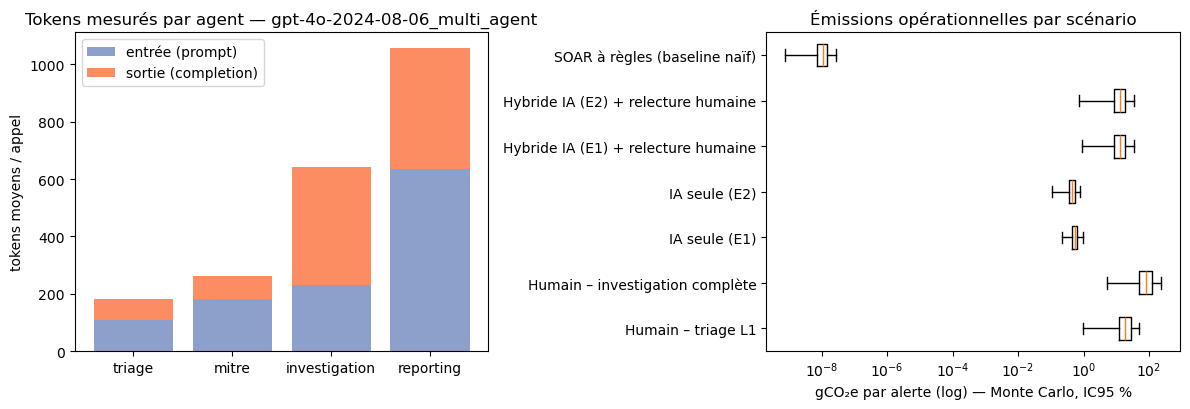

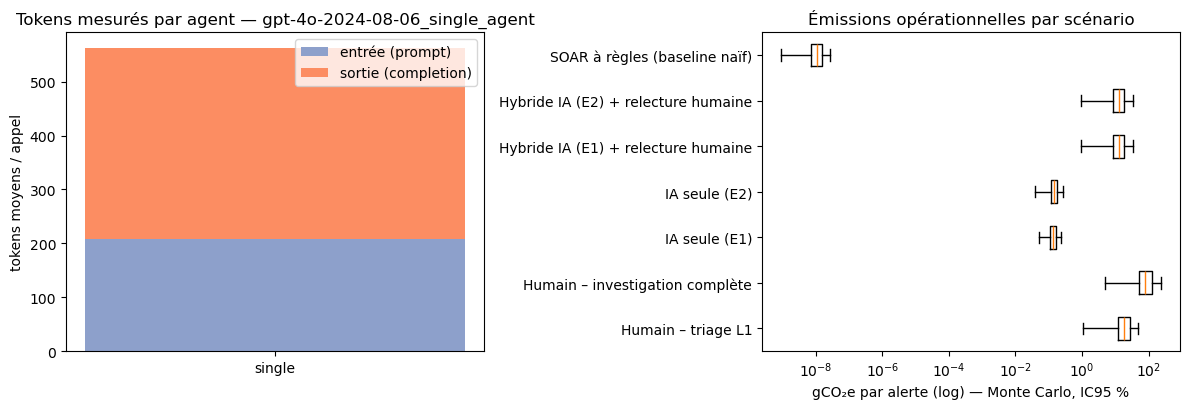

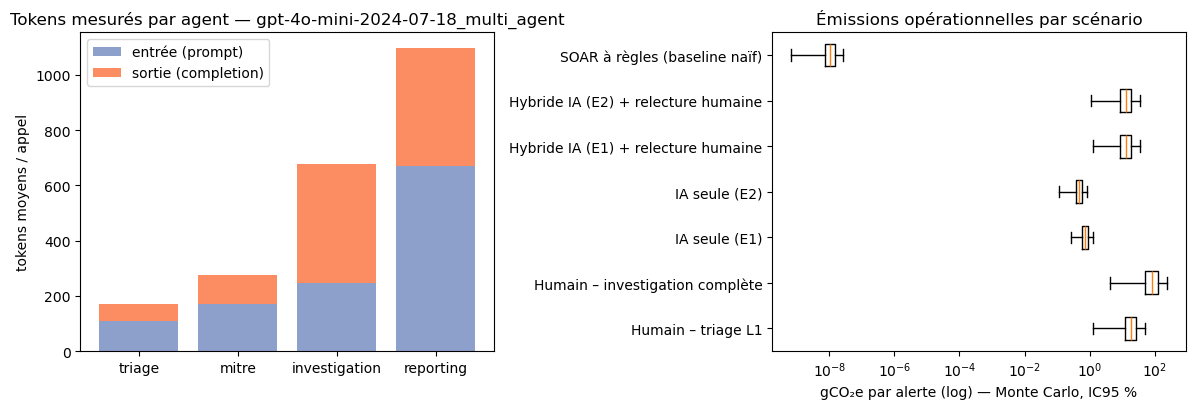

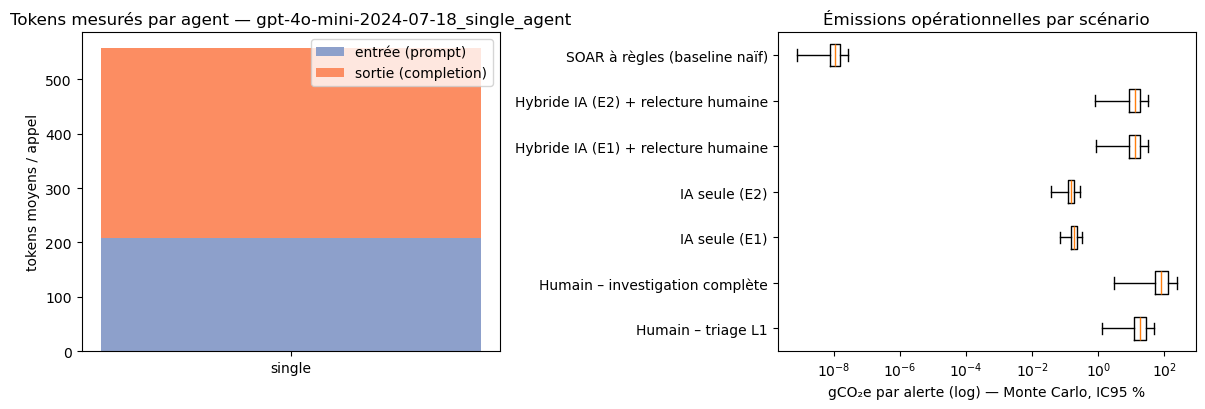

In [28]:
for m, g in per_alert.groupby("model"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    a = agent_stats.loc[m]
    axes[0].bar(a.index, a["prompt_tokens"], label="entrée (prompt)", color="#8DA0CB")
    axes[0].bar(a.index, a["completion_tokens"], bottom=a["prompt_tokens"], label="sortie (completion)", color="#FC8D62")
    axes[0].set_ylabel("tokens moyens / appel"); axes[0].set_title(f"Tokens mesurés par agent — {m}"); axes[0].legend()
    d = MC_DRAWS[m]
    names = list(d.keys())
    axes[1].boxplot([d[k] for k in names], vert=False, showfliers=False)
    axes[1].set_yticks(range(1, len(names) + 1), names); axes[1].set_xscale("log")
    axes[1].set_xlabel("gCO₂e par alerte (log) — Monte Carlo, IC95 %")
    axes[1].set_title("Émissions opérationnelles par scénario")
    fig.tight_layout(); fig.savefig(OUT_DIR / f"fig_tokens_co2_{m}.png", dpi=300); plt.show()

## Alertes SIEM verbeuses : run apparié et validation de la mise à l'échelle



In [29]:
VERBOSE_DIR = Path("outputs") / VERBOSE_RUN_ID
V_CALL_LOG, V_OUTPUT_LOG, V_FAILURE_LOG = (VERBOSE_DIR / "llm_calls.jsonl", VERBOSE_DIR / "alert_outputs.jsonl",
                                           VERBOSE_DIR / "failures.jsonl")
VERBOSE_DONE = False
valerts = None
if not Path(VERBOSE_ALERTS_PATH).exists():
    print(f"⚠️  {VERBOSE_ALERTS_PATH} absent : exécutez `python make_alerts_verbose.py` (R2.1 non traité).")
else:
    valerts = pd.read_csv(VERBOSE_ALERTS_PATH, encoding="utf-8")
    for c in ["alert_id", "pair_id", "variant", "alert", "label"]:
        assert c in valerts.columns, f"Colonne {c} manquante dans {VERBOSE_ALERTS_PATH}"
    valerts["alert_id"] = valerts["alert_id"].astype(str); valerts["pair_id"] = valerts["pair_id"].astype(str)
    verbose_sha256 = hashlib.sha256(Path(VERBOSE_ALERTS_PATH).read_bytes()).hexdigest()
    valerts["n_chars"] = valerts["alert"].str.len()
    n_auth = int(valerts["source"].astype(str).str.startswith("authentic").sum()) if "source" in valerts else 0
    print(f"{len(valerts)} alertes ({valerts.variant.value_counts().to_dict()}) | dont authentiques : {n_auth} | SHA-256 = {verbose_sha256}")
    print(valerts.groupby("variant")["n_chars"].describe().round(0))

    # ------------------------------------------------------------------ exécution (reprise automatique)
    if RUN_VERBOSE:
        VERBOSE_DIR.mkdir(parents=True, exist_ok=True)
        vdone = set()
        if V_OUTPUT_LOG.exists():
            vdone = {(r["model"], r["repeat"], r["alert_id"])
                     for r in map(json.loads, V_OUTPUT_LOG.read_text(encoding="utf-8").splitlines())}
        n_vtot = len(MODELS) * len(ARCHITECTURES) * N_REPEATS * len(valerts)
        print(f"Run verbeux : {len(vdone)}/{n_vtot} traitements déjà présents dans {VERBOSE_DIR.resolve()}")
        if not DRY_RUN and len(vdone) == 0 and os.environ.get("SOC_CONFIRM_VERBOSE") != "1":
            raise RuntimeError("Nouveau run verbeux (appels API payants). Pour confirmer : "
                               "os.environ['SOC_CONFIRM_VERBOSE'] = '1' puis relancez cette cellule.")
        (VERBOSE_DIR / "prompts.json").write_text((OUT_DIR / "prompts.json").read_text(encoding="utf-8"), encoding="utf-8")
        CALL_LOG_TARGET[0] = V_CALL_LOG
        try:
            t_start = time.time()
            for api_model in MODELS:
                for arch in ARCHITECTURES:
                    model = f"{api_model}_{arch}"
                    for rep in range(1, N_REPEATS + 1):
                        for _, row in valerts.sample(frac=1, random_state=SEED + rep).iterrows():
                            key = (model, rep, row["alert_id"])
                            if key in vdone:
                                continue
                            meta = {"run_id": VERBOSE_RUN_ID, "model": model, "api_model": api_model, "arch": arch,
                                    "repeat": rep, "alert_id": row["alert_id"], "pair_id": row["pair_id"],
                                    "variant": row["variant"], "attempt_id": uuid.uuid4().hex}
                            try:
                                out = PIPELINES[arch](row["alert"], api_model, meta)
                                _append(V_OUTPUT_LOG, {**meta, **out}); vdone.add(key)
                            except Exception as e:
                                if type(e).__name__ in ("AuthenticationError", "PermissionDeniedError", "NotFoundError", "BadRequestError"):
                                    raise
                                print(f"✗ {key} : {type(e).__name__}: {e}")
                                _append(V_FAILURE_LOG, {**meta, "error": f"{type(e).__name__}: {e}"})
                        print(f"[verbose] {model} — répétition {rep}/{N_REPEATS} ({time.time()-t_start:.0f}s)")
        finally:
            CALL_LOG_TARGET[0] = CALL_LOG
        print(f"Run verbeux terminé : {len(vdone)}/{n_vtot}.")
    else:
        print("RUN_VERBOSE = False : pas d'exécution (analyse seule si des journaux existent).")

33 alertes ({'verbose': 25, 'control': 8}) | dont authentiques : 0 | SHA-256 = a4014634dbc828acfb307227da00fefead594d535783865c12e7aa69b656ffbe
         count    mean     std     min     25%     50%     75%     max
variant                                                               
control    8.0    78.0    15.0    57.0    69.0    76.0    88.0   102.0
verbose   25.0  4743.0  1442.0  2713.0  3614.0  4083.0  5904.0  7477.0
RUN_VERBOSE = False : pas d'exécution (analyse seule si des journaux existent).


Run verbeux : 990 appels, 0.0% des pipelines avec au moins une réponse tronquée.
Modèles renvoyés : ['gpt-4o-2024-08-06', 'gpt-4o-mini-2024-07-18']

=== R2.1 : facteurs verbeux / court (moyenne par exécution, IC95 % groupé par alerte) ===


configuration,gpt-4o-2024-08-06_multi_agent,gpt-4o-2024-08-06_single_agent,gpt-4o-mini-2024-07-18_multi_agent,gpt-4o-mini-2024-07-18_single_agent
n_alerts,25,25,25,25
ratio_prompt_tokens,7.069908,9.199207,7.025495,9.199207
ratio_prompt_tokens_ci95,6.35 – 7.85,8.28 – 10.18,6.27 – 7.88,8.27 – 10.17
ratio_completion_tokens,1.131916,1.158613,1.144832,1.183387
ratio_completion_tokens_ci95,1.09 – 1.17,1.11 – 1.21,1.10 – 1.19,1.12 – 1.24
ratio_total_tokens,4.331936,4.155797,4.298408,4.218018
ratio_total_tokens_ci95,3.95 – 4.74,3.78 – 4.58,3.89 – 4.75,3.85 – 4.61
ratio_E1_scaled_Wh,1.656706,1.569572,1.245739,1.256661
ratio_E1_scaled_Wh_ci95,1.58 – 1.73,1.50 – 1.65,1.20 – 1.29,1.20 – 1.31
ratio_E2_Wh,1.915536,1.742496,1.913715,1.777092


=== Cache de prompt (les répétitions peuvent réutiliser le préfixe mis en cache) ===


cached_share  latency_s  \
model                               rep_group                                  
gpt-4o-2024-08-06_multi_agent       répétition 1            0.000     12.666   
                                    répétitions 2–3         0.443     11.521   
gpt-4o-2024-08-06_single_agent      répétition 1            0.000      3.743   
                                    répétitions 2–3         0.804      3.623   
gpt-4o-mini-2024-07-18_multi_agent  répétition 1            0.000     14.701   
                                    répétitions 2–3         0.505     14.542   
gpt-4o-mini-2024-07-18_single_agent répétition 1            0.000      6.051   
                                    répétitions 2–3         0.942      6.022   

                                                     E2_Wh  E2_cache_free_Wh  
model                               rep_group                                 
gpt-4o-2024-08-06_multi_agent       répétition 1     2.384             2.384  
                                    répétitions 2–3  2.384             1.818  
gpt-4o-2024-08-06_single_agent      répétition 1     0.714             0.714  
                                    répétitions 2–3  0.716             0.490  
gpt-4o-mini-2024-07-18_multi_agent  répétition 1     2.430             2.430  
                                    répétitions 2–3  2.455             1.840  
gpt-4o-mini-2024-07-18_single_agent répétition 1     0.716             0.716  
                                    répétitions 2–3  0.709             0.454

=== Qualité sur les mêmes incidents : version courte vs verbeuse (MESURÉ) ===


court (mêmes alertes)                      \
                                                 accuracy     f1 mitre_recall   
model                                                                           
gpt-4o-2024-08-06_multi_agent                        1.00  1.000        0.815   
gpt-4o-2024-08-06_single_agent                       1.00  1.000        0.753   
gpt-4o-mini-2024-07-18_multi_agent                   1.00  1.000        0.667   
gpt-4o-mini-2024-07-18_single_agent                  0.96  0.971        0.543   

                                                     \
                                    mitre_precision   
model                                                 
gpt-4o-2024-08-06_multi_agent                 0.641   
gpt-4o-2024-08-06_single_agent                0.693   
gpt-4o-mini-2024-07-18_multi_agent            0.382   
gpt-4o-mini-2024-07-18_single_agent           0.530   

                                                                 verbeux  \
                                    benign_with_techniques_rate accuracy   
model                                                                      
gpt-4o-2024-08-06_multi_agent                             0.375     1.00   
gpt-4o-2024-08-06_single_agent                            0.000     1.00   
gpt-4o-mini-2024-07-18_multi_agent                        0.000     0.96   
gpt-4o-mini-2024-07-18_single_agent                       0.125     1.00   

                                                                         \
                                        f1 mitre_recall mitre_precision   
model                                                                     
gpt-4o-2024-08-06_multi_agent        1.000        0.852           0.335   
gpt-4o-2024-08-06_single_agent       1.000        0.704           0.488   
gpt-4o-mini-2024-07-18_multi_agent   0.971        0.556           0.211   
gpt-4o-mini-2024-07-18_single_agent  1.000        0.531           0.331   

                                                                 
                                    benign_with_techniques_rate  
model                                                            
gpt-4o-2024-08-06_multi_agent                             0.708  
gpt-4o-2024-08-06_single_agent                            0.375  
gpt-4o-mini-2024-07-18_multi_agent                        0.667  
gpt-4o-mini-2024-07-18_single_agent                       0.708

=== Réductions recalculées avec les alertes verbeuses ===


,model,IA,référence,nature,p2.5,médiane,p97.5,P(réduction>0)
0,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,Humain – triage L1,ESTIMÉ (tokens verbeux MESURÉS),-62.30,27.68,69.63,0.77
1,gpt-4o-2024-08-06_multi_agent,Hybride IA (E1) + relecture humaine,Humain – triage L1,ESTIMÉ (tokens verbeux MESURÉS),-58.14,29.62,70.87,0.79
2,gpt-4o-2024-08-06_multi_agent,Hybride IA (E2) + relecture humaine,Humain – investigation complète,ESTIMÉ (tokens verbeux MESURÉS),54.78,83.69,94.00,1.00
3,gpt-4o-2024-08-06_multi_agent,IA seule (E2),Humain – investigation complète,ESTIMÉ (tokens verbeux MESURÉS),95.23,98.97,99.74,1.00
4,gpt-4o-2024-08-06_multi_agent,IA seule (E1),Humain – investigation complète,ESTIMÉ (tokens verbeux MESURÉS),97.13,99.35,99.81,1.00
5,gpt-4o-2024-08-06_single_agent,Hybride IA (E2) + relecture humaine,Humain – triage L1,ESTIMÉ (tokens verbeux MESURÉS),-54.45,31.40,72.33,0.81
6,gpt-4o-2024-08-06_single_agent,Hybride IA (E1) + relecture humaine,Humain – triage L1,ESTIMÉ (tokens verbeux MESURÉS),-53.19,32.19,72.80,0.81
7,gpt-4o-2024-08-06_single_agent,Hybride IA (E2) + relecture humaine,Humain – investigation complète,ESTIMÉ (tokens verbeux MESURÉS),56.65,84.63,94.35,1.00
8,gpt-4o-2024-08-06_single_agent,IA seule (E2),Humain – investigation complète,ESTIMÉ (tokens verbeux MESURÉS),98.59,99.69,99.92,1.00
9,gpt-4o-2024-08-06_single_agent,IA seule (E1),Humain – investigation complète,ESTIMÉ (tokens verbeux MESURÉS),99.28,99.83,99.95,1.00


=== Dérive sur les alertes de contrôle (texte identique ; 0 % attendu pour l'entrée) ===


,prompt_diff_%_moyenne,prompt_diff_%_max_abs,completion_diff_%_moyenne,completion_diff_%_max_abs
model,,,,
gpt-4o-2024-08-06_multi_agent,0.36,15.24,0.70,10.67
gpt-4o-2024-08-06_single_agent,0.00,0.00,-2.22,20.08
gpt-4o-mini-2024-07-18_multi_agent,-1.89,15.55,-1.26,11.71
gpt-4o-mini-2024-07-18_single_agent,0.00,0.00,-0.01,35.38


system_fingerprint — run_final : ['fp_0157cc0427', 'fp_01a55b9f25', 'fp_01ca53b73a', 'fp_07d47c81e6'] | run verbeux : ['fp_04490942cc', 'fp_06e34e0f8b', 'fp_0e7150ae59', 'fp_291119301d'] | DIFFÉRENTS → mentionner la mise à jour du service


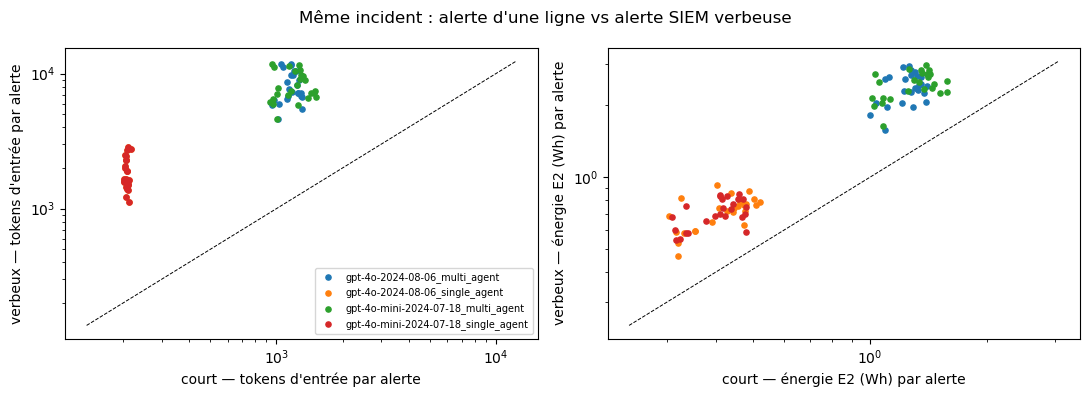

In [30]:
if valerts is not None and V_OUTPUT_LOG.exists() and V_CALL_LOG.exists():
    vcalls = pd.read_json(V_CALL_LOG, lines=True, encoding="utf-8")
    vout = pd.read_json(V_OUTPUT_LOG, lines=True, encoding="utf-8")
    for _df in (vcalls, vout):
        _df["alert_id"] = _df["alert_id"].astype(str)
        _df["api_model"], _df["arch"] = zip(*_df["model"].map(_split_config))
    vcalls_ok = vcalls[vcalls["attempt_id"].isin(set(vout["attempt_id"]))]
    v_alert = vcalls_ok.groupby(KEYS).agg(
        n_queries=("agent", "size"), prompt_tokens=("prompt_tokens", "sum"),
        completion_tokens=("completion_tokens", "sum"), total_tokens=("total_tokens", "sum"),
        cached_prompt_tokens=("cached_prompt_tokens", "sum"), latency_s=("latency_s", "sum"),
        truncated=("finish_reason", lambda s: (s == "length").any())).reset_index()
    v_alert = v_alert.merge(valerts[["alert_id", "pair_id", "variant"] + (["source"] if "source" in valerts else [])],
                            on="alert_id")
    v_alert["api_model"], v_alert["arch"] = zip(*v_alert["model"].map(_split_config))
    v_alert["e1_factor"] = v_alert["api_model"].map(E1_FACTOR).fillna(1.0)
    _fitv = np.vstack(v_alert["api_model"].map(lambda m: JFIT.get(m, JFIT[REF_MODEL])))
    v_alert["E1_scaled_Wh"] = _fitv[:, 0] * v_alert["prompt_tokens"] + _fitv[:, 1] * v_alert["completion_tokens"] + _fitv[:, 2] * v_alert["n_queries"]
    v_alert["E2_Wh"] = e2_wh(v_alert["prompt_tokens"], v_alert["completion_tokens"], CENTRAL)
    # Borne basse si les tokens mis en cache ne coûtaient rien au prefill
    v_alert["E2_cache_free_Wh"] = e2_wh(v_alert["prompt_tokens"] - v_alert["cached_prompt_tokens"], v_alert["completion_tokens"], CENTRAL)
    print(f"Run verbeux : {len(vcalls)} appels, {v_alert['truncated'].mean():.1%} des pipelines avec au moins une réponse tronquée.")
    print("Modèles renvoyés :", vcalls["model_returned"].unique().tolist())

    # ---------------------------------------------------------- 1) facteurs appariés verbeux / court
    short = per_alert.rename(columns={"alert_id": "pair_id"})[
        ["model", "repeat", "pair_id", "prompt_tokens", "completion_tokens", "total_tokens", "latency_s",
         "E1_scaled_Wh", "E2_Wh", "n_queries"]]
    pair = v_alert[v_alert.variant == "verbose"].merge(short, on=["model", "repeat", "pair_id"], suffixes=("_v", "_s"))
    for c in ["prompt_tokens", "completion_tokens", "total_tokens", "latency_s", "E1_scaled_Wh", "E2_Wh"]:
        pair[f"ratio_{c}"] = pair[f"{c}_v"] / pair[f"{c}_s"]
    # 2) prédictions de la mise à l'échelle depuis le run court
    pair["E2_pred_input_only_Wh"] = e2_wh(pair["prompt_tokens_v"], pair["completion_tokens_s"], CENTRAL)
    pair["E2_pred_proportional_Wh"] = pair["E2_Wh_s"] * pair["total_tokens_v"] / pair["total_tokens_s"]
    pair["err_input_only_%"] = 100 * (pair["E2_pred_input_only_Wh"] / pair["E2_Wh_v"] - 1)
    pair["err_proportional_%"] = 100 * (pair["E2_pred_proportional_Wh"] / pair["E2_Wh_v"] - 1)

    rows = []
    for m, g in pair.groupby("model"):
        r = {"configuration": m, "n_alerts": g["pair_id"].nunique()}
        for c in ["ratio_prompt_tokens", "ratio_completion_tokens", "ratio_total_tokens", "ratio_E1_scaled_Wh",
                  "ratio_E2_Wh", "ratio_latency_s", "err_input_only_%", "err_proportional_%"]:
            s = describe_clustered(g, c, cluster="pair_id")
            r[c] = s["mean"]; r[c + "_ci95"] = f"{s['ci95_low']:.2f} – {s['ci95_high']:.2f}"
        rows.append(r)
    verbose_scaling = pd.DataFrame(rows).set_index("configuration")
    print("\n=== R2.1 : facteurs verbeux / court (moyenne par exécution, IC95 % groupé par alerte) ===")
    display(verbose_scaling.T)

    # ---------------------------------------------------------- 3) cache de prompt
    v_alert["cached_share"] = v_alert["cached_prompt_tokens"] / v_alert["prompt_tokens"]
    cache = v_alert[v_alert.variant == "verbose"].assign(rep_group=lambda d: np.where(d.repeat == 1, "répétition 1", "répétitions 2–3")) \
        .groupby(["model", "rep_group"]).agg(cached_share=("cached_share", "mean"), latency_s=("latency_s", "mean"),
                                            E2_Wh=("E2_Wh", "mean"), E2_cache_free_Wh=("E2_cache_free_Wh", "mean"))
    print("=== Cache de prompt (les répétitions peuvent réutiliser le préfixe mis en cache) ===")
    display(cache.round(3))

    # ---------------------------------------------------------- 4) qualité verbeuse vs courte (mêmes alertes)
    vout["pred"] = vout["triage"].map(lambda s: norm_label(parse_json(s).get("verdict", "")))
    vout["pred_mitre"] = vout["mitre"].map(pred_techniques)
    vq_alerts = valerts[["alert_id", "label"] + (["mitre_gt"] if "mitre_gt" in valerts else [])]
    vqual, _ = quality_by_repeat(vout[vout["alert_id"].isin(valerts.loc[valerts.variant == "verbose", "alert_id"])], vq_alerts)
    pids = valerts.loc[valerts.variant == "verbose", "pair_id"]
    squal, _ = quality_by_repeat(outputs[outputs["alert_id"].isin(pids)], alerts_df)
    qcols = [c for c in ["accuracy", "f1", "mitre_recall", "mitre_precision", "benign_with_techniques_rate"] if c in vqual]
    verbose_quality = pd.concat({"court (mêmes alertes)": squal.groupby("model")[qcols].mean(),
                                 "verbeux": vqual.groupby("model")[qcols].mean()}, axis=1)
    print("=== Qualité sur les mêmes incidents : version courte vs verbeuse (MESURÉ) ===")
    display(verbose_quality.round(3))

    # ---------------------------------------------------------- 5) réduction CO2 avec tokens verbeux
    vred = []
    for m, g in v_alert[v_alert.variant == "verbose"].groupby("model"):
        p = sample_params(N_MC)
        _, co2 = scenarios(p, tok_arrays(g, RNG.integers(0, len(g), N_MC)))
        for ai, hu in COMPARISONS:
            red = 100 * (1 - co2[ai] / co2[hu])
            vred.append({"model": m, "IA": ai, "référence": hu, "nature": "ESTIMÉ (tokens verbeux MESURÉS)",
                         **pct(red), "P(réduction>0)": (red > 0).mean()})
    verbose_reductions = pd.DataFrame(vred)
    print("=== Réductions recalculées avec les alertes verbeuses ===")
    display(verbose_reductions.round(2))

    # ---------------------------------------------------------- 6) dérive : alertes de contrôle
    ctrl = v_alert[v_alert.variant == "control"].merge(short, on=["model", "repeat", "pair_id"], suffixes=("_v", "_s"))
    drift = None
    if len(ctrl):
        ctrl["prompt_diff_%"] = 100 * (ctrl["prompt_tokens_v"] / ctrl["prompt_tokens_s"] - 1)
        ctrl["completion_diff_%"] = 100 * (ctrl["completion_tokens_v"] / ctrl["completion_tokens_s"] - 1)
        drift = ctrl.groupby("model")[["prompt_diff_%", "completion_diff_%"]].agg(["mean", lambda s: s.abs().max()])
        drift.columns = [f"{a}_{'moyenne' if b == 'mean' else 'max_abs'}" for a, b in drift.columns]
        print("=== Dérive sur les alertes de contrôle (texte identique ; 0 % attendu pour l'entrée) ===")
        display(drift.round(2))
        fp_ref = set(calls["system_fingerprint"].dropna()); fp_v = set(vcalls["system_fingerprint"].dropna())
        print(f"system_fingerprint — run_final : {sorted(fp_ref)[:4]} | run verbeux : {sorted(fp_v)[:4]} | "
              f"{'identiques' if fp_ref == fp_v else 'DIFFÉRENTS → mentionner la mise à jour du service'}")

    # ---------------------------------------------------------- figure + exports
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for m, g in pair.groupby("model"):
        gm = g.groupby("pair_id")[["prompt_tokens_s", "prompt_tokens_v", "E2_Wh_s", "E2_Wh_v"]].mean()
        axes[0].scatter(gm["prompt_tokens_s"], gm["prompt_tokens_v"], s=14, label=m)
        axes[1].scatter(gm["E2_Wh_s"], gm["E2_Wh_v"], s=14, label=m)
    for ax, lab in zip(axes, ["tokens d'entrée par alerte", "énergie E2 (Wh) par alerte"]):
        lim = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
        ax.plot(lim, lim, "k--", lw=.7); ax.set_xlabel(f"court — {lab}"); ax.set_ylabel(f"verbeux — {lab}")
        ax.set_xscale("log"); ax.set_yscale("log")
    axes[0].legend(fontsize=7); fig.suptitle("Même incident : alerte d'une ligne vs alerte SIEM verbeuse")
    fig.tight_layout(); fig.savefig(OUT_DIR / "fig_verbose_vs_short.png", dpi=300); plt.show()

    pair.to_csv(OUT_DIR / "verbose_pairs.csv", index=False)
    verbose_scaling.to_csv(OUT_DIR / "verbose_scaling.csv")
    cache.to_csv(OUT_DIR / "verbose_prompt_cache.csv")
    verbose_quality.to_csv(OUT_DIR / "verbose_quality.csv")
    verbose_reductions.to_csv(OUT_DIR / "verbose_reductions.csv", index=False)
    if drift is not None:
        drift.to_csv(OUT_DIR / "verbose_control_drift.csv")
    VERBOSE_DONE = True
else:
    print("Pas de journaux du run verbeux : R2.1 non encore traité (voir cellule précédente).")

In [31]:
per_alert.to_csv(OUT_DIR / "per_alert.csv", index=False)
token_stats.to_csv(OUT_DIR / "token_stats.csv")
agent_stats.to_csv(OUT_DIR / "agent_stats.csv")
reconciliation.to_csv(OUT_DIR / "reconciliation.csv")
theoretical.to_csv(OUT_DIR / "theoretical_model.csv")
central_table.to_csv(OUT_DIR / "central_estimates.csv", index=False)
mc_co2.to_csv(OUT_DIR / "mc_co2.csv", index=False)
mc_red.to_csv(OUT_DIR / "mc_reductions.csv", index=False)
mc_annual.to_csv(OUT_DIR / "mc_annual.csv", index=False)
tornado.to_csv(OUT_DIR / "tornado.csv", index=False)
grid.to_csv(OUT_DIR / "grid_scenarios.csv", index=False)
projection.to_csv(OUT_DIR / "projection_reasoning.csv", index=False)
if quality is not None:
    quality.to_csv(OUT_DIR / "quality.csv", index=False)
if soar_quality is not None:
    (OUT_DIR / "soar_quality.json").write_text(json.dumps(soar_quality, indent=2, default=float), encoding="utf-8")
(OUT_DIR / "params.json").write_text(json.dumps(
    {"params": PARAMS, "n_queries_theoretical": N_QUERIES_THEORETICAL, "n_monte_carlo": N_MC}, indent=2, ensure_ascii=False), encoding="utf-8")


def _ver(pkg):
    try:
        from importlib.metadata import version
        return version(pkg)
    except Exception:
        return None


env = {"run_id": RUN_ID, "dry_run": DRY_RUN, "date_utc": dt.datetime.now(dt.timezone.utc).isoformat(),
       "python": sys.version, "platform": platform.platform(),
       "packages": {p: _ver(p) for p in ["openai", "pandas", "numpy", "matplotlib"]},
       "models_requested": MODELS, "architectures": ARCHITECTURES, "energy_benchmark_per_model": JEGHAM_T4, "models_returned": sorted(calls["model_returned"].unique().tolist()),
       "system_fingerprints": sorted(calls["system_fingerprint"].dropna().unique().tolist()),
       "n_alerts": len(alerts_df), "n_repeats": N_REPEATS, "dataset_sha256": dataset_sha256,
       "n_llm_calls": len(calls), "n_failures": sum(1 for _ in open(FAILURE_LOG, encoding="utf-8")) if FAILURE_LOG.exists() else 0,
       "seed": SEED, "temperature": TEMPERATURE, "top_p": TOP_P, "max_tokens": MAX_TOKENS,
       "prompt_version": PROMPT_VERSION, "notebook_version": "v3",
       "verbose_run_id": VERBOSE_RUN_ID, "verbose_dataset_sha256": globals().get("verbose_sha256"),
       "model_shutdown_dates": globals().get("MODEL_SHUTDOWN", {})}
(OUT_DIR / "environment.json").write_text(json.dumps(env, indent=2), encoding="utf-8")


def to_latex(df, caption, label, fmt="{:.4g}"):
    df = df.reset_index() if not isinstance(df.index, pd.RangeIndex) else df
    esc = lambda s: str(s).replace("%", r"\%").replace("_", r"\_").replace("&", r"\&").replace("#", r"\#")
    cell = lambda x: esc(fmt.format(x)) if isinstance(x, (float, np.floating)) else esc(x)
    lines = [r"\begin{table}[!t]", r"\centering", rf"\caption{{{caption}}}", rf"\label{{{label}}}",
             r"\begin{tabular}{" + "l" * df.shape[1] + "}", r"\hline",
             " & ".join(esc(c) for c in df.columns) + r" \\", r"\hline"]
    lines += [" & ".join(cell(x) for x in row) + r" \\" for row in df.itertuples(index=False)]
    lines += [r"\hline", r"\end{tabular}", r"\end{table}", ""]
    return "\n".join(lines)


tex = [to_latex(token_stats.reset_index()[lambda d: d.metric.isin(["total_tokens", "prompt_tokens", "completion_tokens"])],
                "Measured token usage per alert (mean, SD between alerts, 95\\% CI from a cluster bootstrap over alerts)", "tab:tokens"),
       to_latex(reconciliation.T.reset_index(), "Reconciliation of query- and token-based energy estimators", "tab:recon"),
       to_latex(mc_red.drop(columns="model"), "CO$_2$ reduction (\\%) with Monte Carlo 95\\% interval", "tab:reduction"),
       to_latex(mc_annual.drop(columns="model"), "Extrapolated annual savings (kgCO$_2$e/yr)", "tab:annual")]
if quality is not None:
    tex.insert(1, to_latex(quality.drop(columns="model"), "Triage quality against ground truth, per repeat", "tab:quality", "{:.3f}"))
if globals().get("table4") is not None:
    tex.append(to_latex(table4.pivot(index="metric", columns="configuration", values="mean_over_repeats"),
                        "ATT\\&CK mapping metrics (mean over repeats; averaging described in the text)", "tab:mitre", "{:.3f}"))
if globals().get("PAIRED_ARCH_DONE"):
    tex.append(to_latex(paired_arch.drop(columns=["CI excludes no-effect"]), "Four-agent vs single-agent pipeline: paired ratios (cost) and differences (quality), 95\\% CI from a paired cluster bootstrap over alerts", "tab:paired"))
if globals().get("VERBOSE_DONE"):
    tex.append(to_latex(verbose_scaling.T, "Verbose SIEM alerts vs single-line alerts: paired scaling factors", "tab:verbose"))
if globals().get("LIFECYCLE_DONE"):
    tex.append(to_latex(lifecycle_red.drop(columns="model"), "Projected lifecycle (operational + embodied) CO$_2$e and water reductions", "tab:lifecycle"))
(OUT_DIR / "tables.tex").write_text("\n".join(tex), encoding="utf-8")

print("Fichiers exportés dans", OUT_DIR.resolve())
for f in sorted(OUT_DIR.iterdir()):
    print(f"  {f.name:32s} {f.stat().st_size/1024:8.1f} Ko")

Fichiers exportés dans C:\Users\a847071\Downloads\soc-energy-repo\outputs\run_final
  agent_stats.csv                       1.0 Ko
  alert_outputs.jsonl                3322.2 Ko
  alerts_anonymized.csv                10.0 Ko
  breakeven_human_minutes.csv           2.2 Ko
  central_estimates.csv                 3.1 Ko
  ci_comparison.csv                     2.2 Ko
  configuration_comparison.csv          1.1 Ko
  environment.json                      3.7 Ko
  estimates_wording_en.md              12.5 Ko
  failures.jsonl                        0.5 Ko
  fig_breakeven_minutes.png           132.9 Ko
  fig_sample_size_gpt-4o-2024-08-06_multi_agent.png    108.4 Ko
  fig_sample_size_gpt-4o-2024-08-06_single_agent.png     99.7 Ko
  fig_sample_size_gpt-4o-mini-2024-07-18_multi_agent.png    107.5 Ko
  fig_sample_size_gpt-4o-mini-2024-07-18_single_agent.png    103.9 Ko
  fig_tokens_co2_gpt-4o-2024-08-06_multi_agent.png    214.3 Ko
  fig_tokens_co2_gpt-4o-2024-08-06_single_agent.png    205.9 Ko
  fi